# COMP4318/5318 Assignment 2: Image Classification

### Group number: 163  , SID1: 530210074 , SID2: 540868894, SID3: 550220550, SID4: 550574604

This notebook classifies 28×28 RGB colorectal histology patches (PathMNIST) into nine tissue types with five models that share one data pipeline and one evaluation protocol:

| Role | Model | Why it is here |
|---|---|---|
| Reference baseline | Dummy (most-frequent) | Floor set by class imbalance alone |
| Reference baseline | Nearest Centroid | Simplest geometric classifier in raw pixel space |
| Algorithm from weeks 1–6 | Gaussian Naive Bayes | Fast probabilistic model with a strong independence assumption |
| Fully connected network | MLP | Learns non-linear pixel interactions, but ignores spatial layout |
| Convolutional network | CNN | Local receptive fields and weight sharing designed for images |

**How to run.** Cells run top-to-bottom in a fresh kernel. The hyperparameter searches in Section 3 are expensive. Their outputs are preserved below, and they are skipped unless `A2_RUN_TUNING=1` is set. Sections 4 and later never depend on them. Data are read from the relative folder `Assignment2Data/`, exactly as in the template, and generated tables and figures go to `results/`.

**Reproducibility note.** All randomness is seeded (`5318`), TensorFlow runs on CPU with deterministic kernels, and the software stack is pinned and packaged in a Docker image (see *Setup*). Even so, we found that **the neural-network results can differ slightly between CPU models and operating-system platforms**. Fixing the software does not fix how a given processor executes floating-point arithmetic: different vector instruction sets change the order in which sums are accumulated, and SGD amplifies these last-bit differences over thousands of updates. GaussianNB and the two baselines were bit-for-bit identical on every platform we tried. Section 4 documents what we observed.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

**Pinned software stack** (identical in the Docker image and in `environment/requirements-lock.txt`):

| Package | Version | Package | Version |
|---|---|---|---|
| Python | 3.11.11 | TensorFlow (CPU) | 2.17.1 |
| NumPy | 1.26.4 | Keras | 3.6.0 |
| pandas | 2.2.3 | scikit-learn | 1.5.2 |
| SciPy | 1.14.1 | Matplotlib | 3.9.2 |

Only Keras, scikit-learn, NumPy, pandas and Matplotlib are used for modelling and plotting. The lock file pins every transitive dependency (84 packages), not just the top-level ones, so the same wheels are installed on every rebuild.

**Controlled environment (recommended).** The package ships a Docker definition based on `python:3.11.11-slim-bookworm` (`linux/amd64`). It runs with no network access, mounts the data and notebook read-only, and limits the container to 4 CPUs and 10 GB of memory, with fixed thread counts. Run from the package root:

```bash
docker compose -f environment/compose.yaml build                 # build the pinned image once
docker compose -f environment/compose.yaml run --rm a2           # fresh-kernel run, final models only
docker compose -f environment/compose.yaml run --rm a2 --tune    # also re-run all searches
```

*Note:* on CPU-only machines TensorFlow 2.17 prints three harmless `Unable to register cuFFT/cuDNN/cuBLAS factory` messages when it is imported (next code cell). They concern GPU plug-ins that are not used here and can be ignored.

**Local alternative.** Create a Python 3.11 environment and run `pip install -r environment/requirements-lock.txt`, or set the flag in the next cell, then open this notebook from the package root.

In [1]:
# Optional: install the pinned stack into the *current* kernel environment (not needed inside Docker).
# Set to True only in a fresh Python 3.11 environment, run this cell, then restart the kernel.
INSTALL_PINNED_REQUIREMENTS = False

if INSTALL_PINNED_REQUIREMENTS:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", "environment/requirements-lock.txt"])

In [2]:
import os
# These must be set before TensorFlow is imported.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # silence TensorFlow info logs
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")      # deterministic kernels
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")     # CPU only, so every run takes the same code path
os.environ.setdefault("PYTHONHASHSEED", "5318")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import gc, hashlib, json, platform, re, sys, warnings
from itertools import product
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from IPython.display import display, Markdown

import sklearn
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import NearestCentroid

import tensorflow as tf
from tensorflow import keras

SEED = 5318
keras.utils.set_random_seed(SEED)                # seeds Python `random`, NumPy and TensorFlow together
tf.config.experimental.enable_op_determinism()   # raise an error rather than silently use a non-deterministic op
try:                                             # fixed thread counts -> fixed work partitioning
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass                                         # threads were already initialised (cell re-run)

# Hyperparameter searches (Section 3) are expensive; their preserved outputs are shown below.
# Set the environment variable A2_RUN_TUNING=1 (or change "0" to "1") to re-run them.
RUN_TUNING = os.environ.get("A2_RUN_TUNING", "0") == "1"

RESULTS_DIR = Path(os.environ.get("A2_RESULTS_DIR", "results"))
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# PathMNIST label names (MedMNIST v2 metadata), in label order 0-8.
CLASS_NAMES = ["Adipose", "Background", "Debris", "Lymphocytes", "Mucus", "Smooth muscle",
               "Normal colon mucosa", "Cancer-associated stroma", "Colorectal adenocarcinoma epithelium"]
SHORT_NAMES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]
NUM_CLASSES = len(CLASS_NAMES)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"RUN_TUNING = {RUN_TUNING}; results directory = {RESULTS_DIR.resolve()}")

2026-10-28 16:42:09.024270: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-28 16:42:09.053495: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-28 16:42:09.061126: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


RUN_TUNING = True; results directory = /home/claude/pkg/a2-submission/results


In [3]:
# Record the exact software *and hardware* of this run. The CPU model and its vector instruction
# sets are logged because they turned out to matter for neural-network reproducibility (Section 4).
PINNED = {"python": "3.11.11", "numpy": "1.26.4", "pandas": "2.2.3", "scipy": "1.14.1",
          "scikit-learn": "1.5.2", "matplotlib": "3.9.2", "tensorflow": "2.17.1", "keras": "3.6.0"}
installed = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
             "matplotlib": matplotlib.__version__, "tensorflow": tf.__version__, "keras": keras.__version__}

def describe_cpu():
    # CPU model name plus the SIMD extensions that determine which numerical kernels are used.
    model, flags = platform.processor() or "unknown", set()
    try:
        info = Path("/proc/cpuinfo").read_text()
        model = re.search(r"model name\s*:\s*(.+)", info).group(1).strip()
        flags = set(re.search(r"flags\s*:\s*(.+)", info).group(1).split())
    except (OSError, AttributeError):
        pass
    simd = [f for f in ("sse4_2", "avx", "avx2", "fma", "avx512f", "avx512_vnni", "avx512_bf16", "amx_tile")
            if f in flags]
    return model, simd

cpu_model, cpu_simd = describe_cpu()
version_table = pd.DataFrame({"pinned": PINNED, "installed": installed})
version_table["matches"] = version_table["pinned"] == version_table["installed"]
display(version_table)
if not version_table["matches"].all():
    warnings.warn("Package versions differ from the pinned stack; results may not match the preserved outputs.")

runtime_environment = {
    **installed, "platform": platform.platform(), "machine": platform.machine(),
    "cpu_model": cpu_model, "cpu_simd_flags": cpu_simd, "logical_cpus": os.cpu_count(),
    "tf_devices": [d.name for d in tf.config.list_physical_devices()],
    "onednn_opts": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default (on for x86)"),
    "seed": SEED, "deterministic_ops": True, "tuning_executed": RUN_TUNING,
    "in_docker": Path("/.dockerenv").exists(),
}
(RESULTS_DIR / "environment.json").write_text(json.dumps(runtime_environment, indent=2))
for key in ("platform", "cpu_model", "cpu_simd_flags", "logical_cpus", "tf_devices", "in_docker"):
    print(f"{key:>15}: {runtime_environment[key]}")

,pinned,installed,matches
python,3.11.11,3.11.11,True
numpy,1.26.4,1.26.4,True
pandas,2.2.3,2.2.3,True
scipy,1.14.1,1.14.1,True
scikit-learn,1.5.2,1.5.2,True
matplotlib,3.9.2,3.9.2,True
tensorflow,2.17.1,2.17.1,True
keras,3.6.0,3.6.0,True


       platform: Linux-6.18.44-fc-v180-x86_64-with-glibc2.39
      cpu_model: Intel(R) Xeon(R) Processor @ 2.80GHz
 cpu_simd_flags: ['sse4_2', 'avx', 'avx2', 'fma', 'avx512f', 'avx512_vnni']
   logical_cpus: 2
     tf_devices: ['/physical_device:CPU:0']
      in_docker: False


## 1. Data loading, exploration, and preprocessing

Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [4]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

In [5]:
# Integrity checks. Labels are stored as uint8; cast to int so that arithmetic on them is safe.
y_train = y_train.reshape(-1).astype(int)
y_test = y_test.reshape(-1).astype(int)
assert X_train.shape == (32000, 28, 28, 3) and X_test.shape == (8000, 28, 28, 3)
assert X_train.dtype == np.uint8 and len(y_train) == len(X_train) and len(y_test) == len(X_test)
assert set(np.unique(y_train)) == set(range(NUM_CLASSES)) and set(np.unique(y_test)) <= set(range(NUM_CLASSES))

# SHA-256 of the supplied files: confirms every run (and every team member) used identical bytes.
EXPECTED_SHA256 = {
    "X_train.npy": "abd9bebaccd42d42505d5f86b5632349e30c47a34b39808e2b92ab69843f33a3",
    "y_train.npy": "76cf03f064af80e4ede8be1826793803a6568549dbcdeef9b4e1f1041f6e094c",
    "X_test.npy":  "644c267fadac9bce1b1c75273f521fa22f92bdd831ed821ee1b8f98e9f861693",
    "y_test.npy":  "c3bed54d86a454329527824d76a507f1dea7e8f91a6efacbb5be9b83acdf6610",
}
for name, expected in EXPECTED_SHA256.items():
    actual = hashlib.sha256(Path("Assignment2Data", name).read_bytes()).hexdigest()
    print(f"{name:<12} {'OK' if actual == expected else 'DIFFERENT FILE'}  {actual[:16]}...")

print(f"\nTraining images: {X_train.shape}, dtype={X_train.dtype}, "
      f"pixel range [{X_train.min()}, {X_train.max()}]")
print(f"Test images:     {X_test.shape}")
print(f"Flattened dimensionality: {np.prod(X_train.shape[1:]):,} features per image")

X_train.npy  OK  abd9bebaccd42d42...
y_train.npy  OK  76cf03f064af80e4...
X_test.npy   OK  644c267fadac9bce...
y_test.npy   OK  c3bed54d86a45432...

Training images: (32000, 28, 28, 3), dtype=uint8, pixel range [0, 255]
Test images:     (8000, 28, 28, 3)
Flattened dimensionality: 2,352 features per image


### 1.1 Class distribution

We first check how the labels are distributed in the supplied training and test sets. The test set is only used here to confirm it follows the training proportions. It is not inspected beyond label counts at any other point before the final evaluation.

,class,abbrev,train_n,test_n,train_%,test_%
0,Adipose,ADI,3490,873,10.91,10.91
1,Background,BACK,3431,858,10.72,10.72
2,Debris,DEB,3505,877,10.95,10.96
3,Lymphocytes,LYM,3656,914,11.42,11.42
4,Mucus,MUC,2950,737,9.22,9.21
5,Smooth muscle,MUS,4290,1072,13.41,13.40
6,Normal colon mucosa,NORM,2728,682,8.52,8.52
7,Cancer-associated stroma,STR,3253,813,10.17,10.16
8,Colorectal adenocarcinoma epithelium,TUM,4697,1174,14.68,14.68


Largest/smallest class ratio: 1.72 (TUM vs NORM)
Majority-class accuracy (the Dummy floor): 0.1468


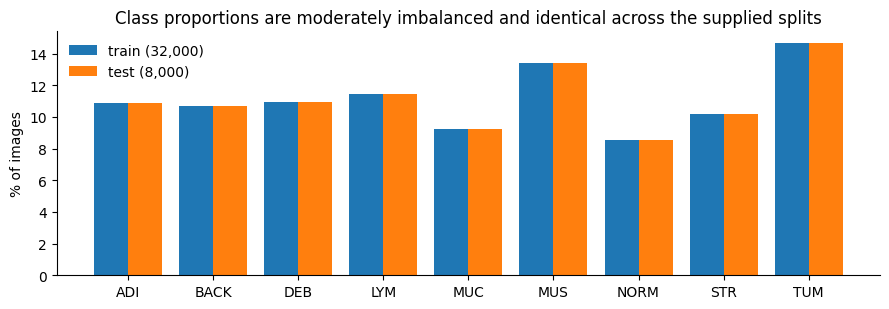

In [6]:
counts = pd.DataFrame({
    "class": CLASS_NAMES, "abbrev": SHORT_NAMES,
    "train_n": np.bincount(y_train, minlength=NUM_CLASSES),
    "test_n": np.bincount(y_test, minlength=NUM_CLASSES),
})
counts["train_%"] = 100 * counts["train_n"] / counts["train_n"].sum()
counts["test_%"] = 100 * counts["test_n"] / counts["test_n"].sum()
display(counts.round(2))
imbalance = counts["train_n"].max() / counts["train_n"].min()
print(f"Largest/smallest class ratio: {imbalance:.2f} "
      f"({SHORT_NAMES[counts['train_n'].idxmax()]} vs {SHORT_NAMES[counts['train_n'].idxmin()]})")
print(f"Majority-class accuracy (the Dummy floor): {counts['train_%'].max() / 100:.4f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(NUM_CLASSES)
ax.bar(x - 0.2, counts["train_%"], 0.4, label="train (32,000)")
ax.bar(x + 0.2, counts["test_%"], 0.4, label="test (8,000)")
ax.set_xticks(x, SHORT_NAMES)
ax.set_ylabel("% of images")
ax.set_title("Class proportions are moderately imbalanced and identical across the supplied splits")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "eda_class_distribution.png"); plt.show()

### 1.2 Development split

To tune hyperparameters without touching the test set, we hold out a **stratified 20 % validation set from the training data only** (25,600 fit / 6,400 validation). Every model sees exactly the same partition. We chose a single hold-out split rather than *k*-fold cross-validation because every neural-network trial costs 15–95 s on our 2-core CPU, so 5-fold CV would have multiplied the search time fivefold. With 6,400 validation images, the standard error of a validation accuracy near 0.7 is about √(0.7·0.3/6400) ≈ 0.006, which is enough to separate the configurations we compare. Differences smaller than about 0.01 should still be treated as ties (see Section 3).

The exploration below uses the **fit partition only**, so that nothing seen during exploration comes from the validation or test images.

In [7]:
fit_idx, val_idx = train_test_split(np.arange(len(y_train)), test_size=0.20,
                                    random_state=SEED, stratify=y_train)
assert len(fit_idx) == 25_600 and len(val_idx) == 6_400 and np.intersect1d(fit_idx, val_idx).size == 0

# Fingerprints of the index arrays: guards against an accidental change of split (e.g. a library
# upgrade changing train_test_split's internals) which would silently invalidate comparisons.
split_fingerprints = {
    "fit_sha256": hashlib.sha256(fit_idx.astype("<i8").tobytes()).hexdigest(),
    "val_sha256": hashlib.sha256(val_idx.astype("<i8").tobytes()).hexdigest(),
}
assert split_fingerprints["fit_sha256"] == "191d1629061294ebe7e01fe7a79ac57739fced43795161a0c6b821241311c571"
assert split_fingerprints["val_sha256"] == "c07d9573b52ee95cb6bd73390fde64f9c2dccd1c2ab14c244a479b1aa0dd3718"
(RESULTS_DIR / "split_fingerprints.json").write_text(json.dumps(split_fingerprints, indent=2))

y_fit, y_val = y_train[fit_idx], y_train[val_idx]
X_fit_raw = X_train[fit_idx]                      # uint8 copy used for exploration
print("Fit / validation sizes:", len(y_fit), len(y_val))
print("Validation class counts:", np.bincount(y_val).tolist())

Fit / validation sizes: 25600 6400
Validation class counts: [698, 686, 701, 731, 590, 858, 546, 651, 939]


### 1.3 What do the classes look like?

Six random fit-partition patches per class show the main visual cues (colour, texture, cell density) and how much they vary *within* each class.

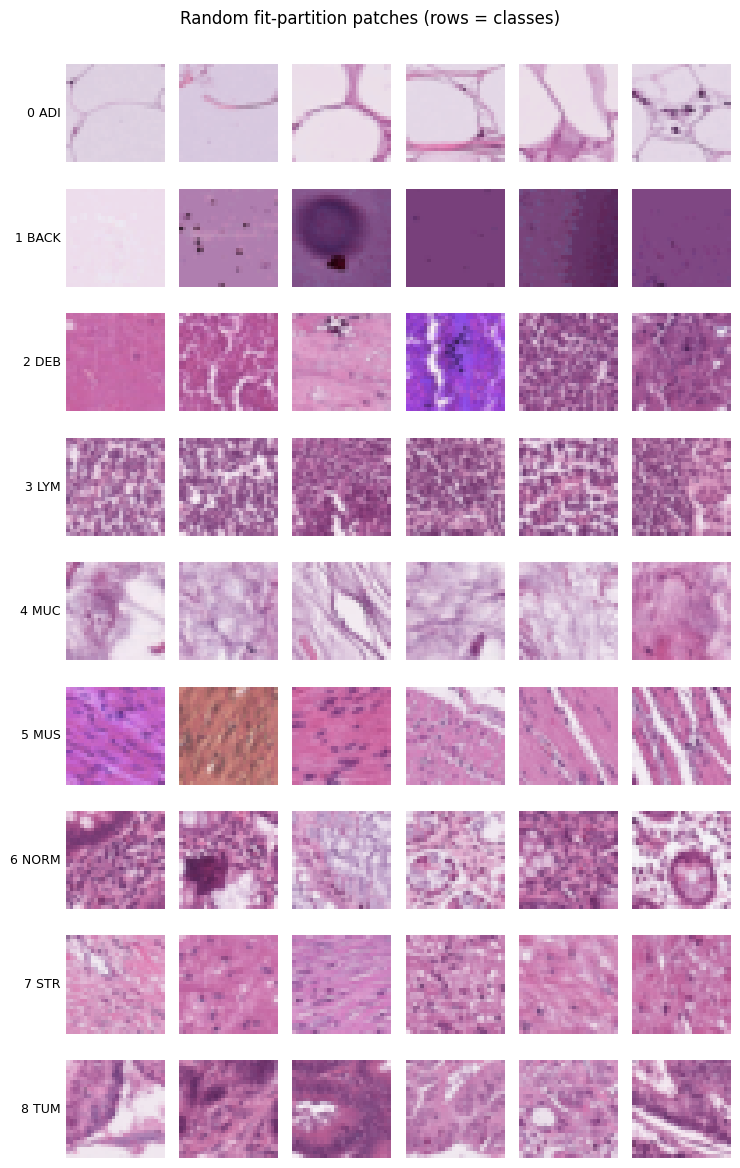

In [8]:
rng = np.random.default_rng(SEED)
n_show = 6
fig, axes = plt.subplots(NUM_CLASSES, n_show, figsize=(n_show * 1.25, NUM_CLASSES * 1.3))
for k in range(NUM_CLASSES):
    for j, idx in enumerate(rng.choice(np.flatnonzero(y_fit == k), n_show, replace=False)):
        ax = axes[k, j]
        ax.imshow(X_fit_raw[idx]); ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_visible(False)
    axes[k, 0].set_ylabel(f"{k} {SHORT_NAMES[k]}", rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random fit-partition patches (rows = classes)", y=1.0)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "eda_class_gallery.png", bbox_inches="tight"); plt.show()

### 1.4 Colour and intensity

H&E staining makes colour informative: nuclei stain purple/blue with haematoxylin, and cytoplasm and stroma stain pink with eosin. We summarise each class by its mean RGB values, its brightness, and the within-image contrast (the standard deviation of pixel values inside one patch, a crude texture measure).

,class,mean_R,mean_G,mean_B,brightness_mean,brightness_sd_between_images,within_image_contrast
0,ADI,0.845,0.762,0.848,0.818,0.036,0.092
1,BACK,0.606,0.432,0.612,0.550,0.194,0.095
2,DEB,0.753,0.485,0.699,0.646,0.060,0.146
3,LYM,0.693,0.494,0.664,0.617,0.044,0.135
4,MUC,0.768,0.602,0.753,0.708,0.052,0.122
5,MUS,0.783,0.521,0.721,0.675,0.058,0.145
6,NORM,0.731,0.524,0.693,0.649,0.061,0.151
7,STR,0.772,0.525,0.716,0.671,0.046,0.128
8,TUM,0.710,0.479,0.663,0.617,0.057,0.151


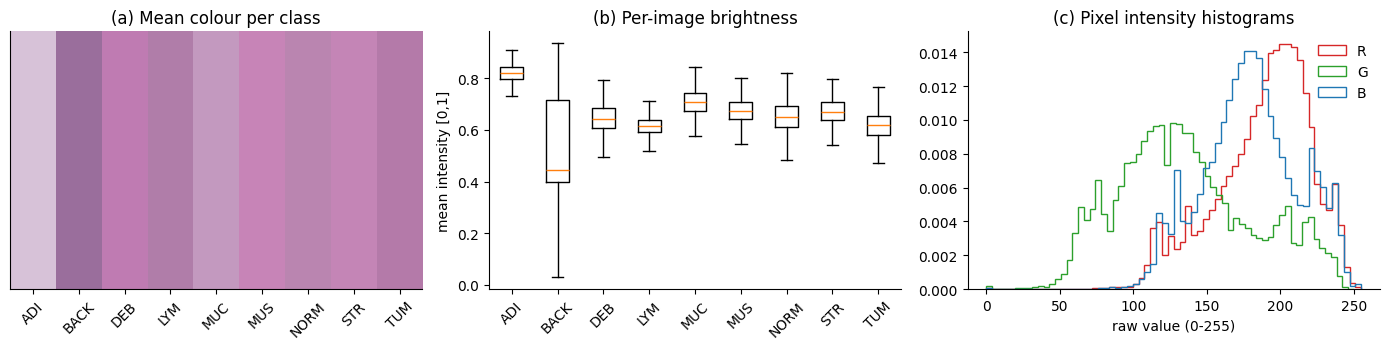

In [9]:
X_fit_float = X_fit_raw.astype(np.float32) / 255.0
img_mean_rgb = X_fit_float.mean(axis=(1, 2))                 # (n, 3) mean colour per image
img_brightness = img_mean_rgb.mean(axis=1)                   # (n,)
img_contrast = X_fit_float.std(axis=(1, 2, 3))               # (n,) within-image texture proxy

colour_stats = pd.DataFrame({
    "class": SHORT_NAMES,
    "mean_R": [img_mean_rgb[y_fit == k, 0].mean() for k in range(NUM_CLASSES)],
    "mean_G": [img_mean_rgb[y_fit == k, 1].mean() for k in range(NUM_CLASSES)],
    "mean_B": [img_mean_rgb[y_fit == k, 2].mean() for k in range(NUM_CLASSES)],
    "brightness_mean": [img_brightness[y_fit == k].mean() for k in range(NUM_CLASSES)],
    "brightness_sd_between_images": [img_brightness[y_fit == k].std() for k in range(NUM_CLASSES)],
    "within_image_contrast": [img_contrast[y_fit == k].mean() for k in range(NUM_CLASSES)],
})
display(colour_stats.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
# (a) mean colour swatches per class
swatch = np.stack([colour_stats[["mean_R", "mean_G", "mean_B"]].to_numpy()])
axes[0].imshow(swatch, aspect="auto"); axes[0].set_yticks([])
axes[0].set_xticks(range(NUM_CLASSES), SHORT_NAMES, rotation=45)
axes[0].set_title("(a) Mean colour per class")
# (b) brightness distribution per class
axes[1].boxplot([img_brightness[y_fit == k] for k in range(NUM_CLASSES)], showfliers=False)
axes[1].set_xticks(range(1, NUM_CLASSES + 1), SHORT_NAMES, rotation=45)
axes[1].set_title("(b) Per-image brightness"); axes[1].set_ylabel("mean intensity [0,1]")
# (c) pixel histograms per channel (whole fit partition)
sample = X_fit_raw[rng.choice(len(X_fit_raw), 4000, replace=False)]
for c, colour in enumerate(("tab:red", "tab:green", "tab:blue")):
    axes[2].hist(sample[..., c].ravel(), bins=64, histtype="step", color=colour, density=True, label="RGB"[c])
axes[2].set_title("(c) Pixel intensity histograms"); axes[2].set_xlabel("raw value (0-255)")
axes[2].legend(frameon=False)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "eda_colour_intensity.png"); plt.show()

### 1.5 Are the images centred? How correlated are the pixels?

Unlike object-recognition datasets, histology patches are crops of continuous tissue, so we would not expect a centred object. We check this with the per-position mean and variance across all fit images. We also measure pixel correlations, because they bear directly on GaussianNB's independence assumption and on the redundancy an MLP has to learn around.

Mean intensity across positions: min 0.657, max 0.661 (spread 0.004)


,feature pair,mean Pearson r
0,horizontal neighbour (1 px),0.867
1,vertical neighbour (1 px),0.875
2,pixels 5 px apart,0.645
3,pixels 14 px apart,0.581
4,"R vs G, same pixel",0.894
5,"R vs B, same pixel",0.923
6,"G vs B, same pixel",0.954


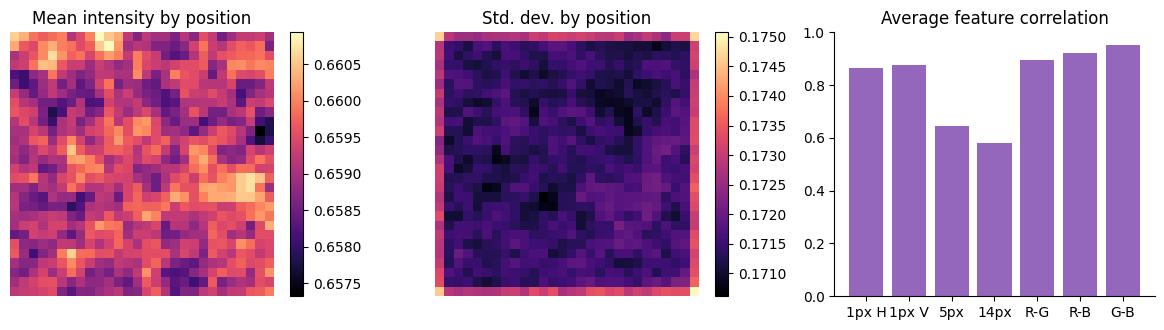

In [10]:
pos_mean = X_fit_float.mean(axis=(0, 3))          # 28x28 mean intensity per spatial position
pos_std = X_fit_float.std(axis=(0, 3))
print(f"Mean intensity across positions: min {pos_mean.min():.3f}, max {pos_mean.max():.3f} "
      f"(spread {pos_mean.max() - pos_mean.min():.3f})")

# Correlation between features, estimated over 5,000 fit images.
Z = X_fit_float[rng.choice(len(X_fit_float), 5000, replace=False)]
Z = (Z - Z.mean(axis=0)) / (Z.std(axis=0) + 1e-8)  # standardise each pixel-channel feature
def mean_corr(a, b):
    return float((a * b).mean())                  # average Pearson r over all position pairs
corr_rows = [
    ("horizontal neighbour (1 px)", mean_corr(Z[:, :, :-1, :], Z[:, :, 1:, :])),
    ("vertical neighbour (1 px)",   mean_corr(Z[:, :-1, :, :], Z[:, 1:, :, :])),
    ("pixels 5 px apart",           mean_corr(Z[:, :, :-5, :], Z[:, :, 5:, :])),
    ("pixels 14 px apart",          mean_corr(Z[:, :, :-14, :], Z[:, :, 14:, :])),
    ("R vs G, same pixel",          mean_corr(Z[..., 0], Z[..., 1])),
    ("R vs B, same pixel",          mean_corr(Z[..., 0], Z[..., 2])),
    ("G vs B, same pixel",          mean_corr(Z[..., 1], Z[..., 2])),
]
pixel_corr = pd.DataFrame(corr_rows, columns=["feature pair", "mean Pearson r"])
display(pixel_corr.round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
im0 = axes[0].imshow(pos_mean, cmap="magma"); axes[0].set_title("Mean intensity by position")
im1 = axes[1].imshow(pos_std, cmap="magma"); axes[1].set_title("Std. dev. by position")
for ax, im in zip(axes[:2], (im0, im1)):
    ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046)
axes[2].bar(range(len(pixel_corr)), pixel_corr["mean Pearson r"], color="tab:purple")
axes[2].set_xticks(range(len(pixel_corr)), ["1px H", "1px V", "5px", "14px", "R-G", "R-B", "G-B"])
axes[2].set_ylim(0, 1); axes[2].set_title("Average feature correlation")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "eda_centring_correlation.png"); plt.show()

### 1.6 How separable are the classes in pixel space?

We project a fit-partition sample onto its first principal components and compute distances between class-mean images (class centroids). The PCA here is purely exploratory: it is fitted to fit-partition data only and is **not** used as a preprocessing step (see 1.8).

80% of pixel variance captured by 51 of 2,352 components
90% of pixel variance captured by 162 of 2,352 components
95% of pixel variance captured by 309 of 2,352 components


Closest class-centroid pairs (Euclidean, raw pixel space): [('MUS', 'STR', 0.39), ('LYM', 'TUM', 0.65), ('DEB', 'NORM', 1.27), ('NORM', 'STR', 1.31), ('DEB', 'STR', 1.32)]


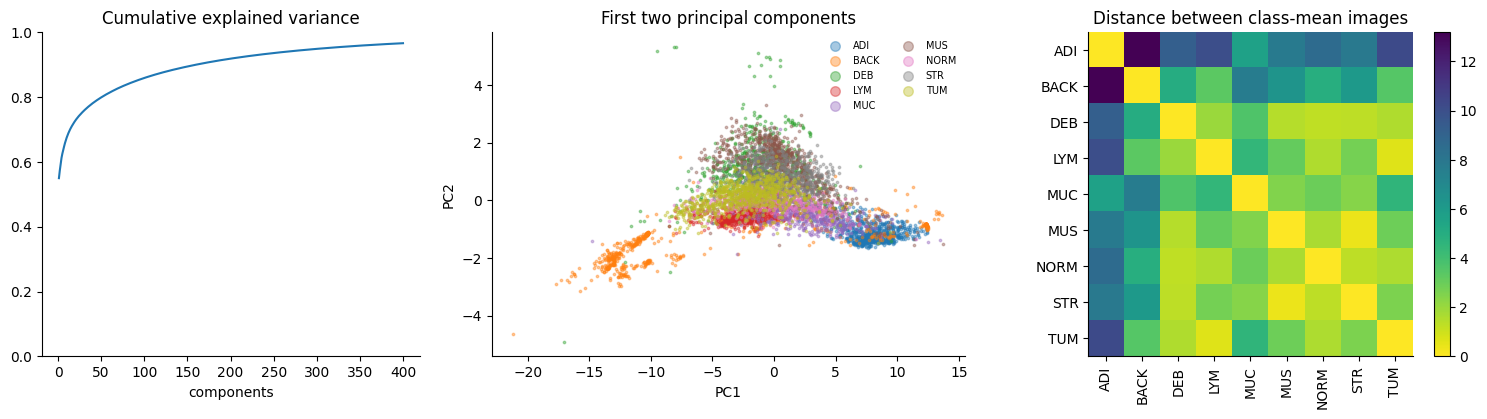

In [11]:
sub = rng.choice(len(X_fit_float), 6000, replace=False)
X_sub, y_sub = X_fit_float[sub].reshape(len(sub), -1), y_fit[sub]
pca = PCA(n_components=400, random_state=SEED).fit(X_sub)
cumvar = np.cumsum(pca.explained_variance_ratio_)
for target in (0.80, 0.90, 0.95):
    print(f"{int(target * 100)}% of pixel variance captured by {np.searchsorted(cumvar, target) + 1} "
          f"of 2,352 components")
proj = pca.transform(X_sub)[:, :2]

centroids = np.stack([X_fit_float[y_fit == k].reshape(-1, 2352).mean(axis=0) for k in range(NUM_CLASSES)])
centroid_dist = np.sqrt(((centroids[:, None, :] - centroids[None, :, :]) ** 2).sum(-1))
closest = sorted(((centroid_dist[i, j], SHORT_NAMES[i], SHORT_NAMES[j])
                  for i in range(NUM_CLASSES) for j in range(i + 1, NUM_CLASSES)))[:5]
print("Closest class-centroid pairs (Euclidean, raw pixel space):",
      [(a, b, round(float(d), 2)) for d, a, b in closest])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.25, 1.1]})
axes[0].plot(np.arange(1, len(cumvar) + 1), cumvar); axes[0].set_xlabel("components"); axes[0].set_ylim(0, 1)
axes[0].set_title("Cumulative explained variance")
cmap = plt.get_cmap("tab10")
for k in range(NUM_CLASSES):
    m = y_sub == k
    axes[1].scatter(proj[m, 0], proj[m, 1], s=3, alpha=0.4, color=cmap(k), label=SHORT_NAMES[k])
axes[1].set_title("First two principal components"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=4, fontsize=7, frameon=False, ncol=2)
im = axes[2].imshow(centroid_dist, cmap="viridis_r")
axes[2].set_xticks(range(NUM_CLASSES), SHORT_NAMES, rotation=90)
axes[2].set_yticks(range(NUM_CLASSES), SHORT_NAMES)
axes[2].set_title("Distance between class-mean images"); fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "eda_pca_centroids.png"); plt.show()
del X_sub, Z

### 1.7 Exploration findings and their consequences

Early in the project we also built a small interactive **Streamlit EDA dashboard** (generated with help from ChatGPT; included in `tools/eda_dashboard/`). It offers class-balanced galleries, RGB histograms, per-class colour statistics, and PCA scatter plots on random training subsets, with the test set hidden by default. It was useful for browsing many patches quickly. The cells above reproduce its key observations in a static, reproducible form. Taken together:

1. **Moderate class imbalance** (ratio ≈ 1.7 between TUM and NORM). The same proportions hold in the test set, so a majority-class predictor already scores ≈ 0.147 accuracy. → We use **Macro-F1** (each class weighted equally) as the selection metric, and report accuracy and balanced accuracy alongside it.
2. **Colour is informative but not sufficient.** ADI is by far the brightest and smoothest class (pale fat cells). BACK is low in texture but has the most *variable* brightness, with a between-image s.d. ≈ 0.19, three times that of any other class, because "background" can be bright glass or dark out-of-tissue regions. LYM and TUM are the darkest, most purple tissue (dense nuclei). The remaining classes (DEB, MUC, MUS, NORM, STR) share pink-purple hues with overlapping brightness ranges. → Colour should be kept, so we do **not** convert to grayscale. Pixel-level colour alone (GaussianNB, Nearest Centroid) should struggle on the pink stromal and epithelial classes.
3. **No centred object.** The mean intensity varies by < 0.005 across the 28×28 positions, so these are texture patches: the same tissue pattern can appear anywhere in the crop. → This favours translation-equivariant convolutions with pooling (CNN) over position-specific weights (MLP).
4. **Pixels are strongly correlated.** Adjacent pixels correlate at r ≈ 0.87, and the R/G/B values of one pixel at r ≈ 0.89–0.95. Correlation decays with distance (≈ 0.64 at 5 px), but a shared, image-wide brightness component remains (≈ 0.57 even 14 px apart). → GaussianNB's conditional-independence assumption is clearly violated: it will count the same evidence many times and become over-confident. The excess dependence is *local*, which is exactly the structure convolutions exploit.
5. **Redundancy and overlap.** The first principal component alone (essentially overall brightness) explains ≈ 55 % of the pixel variance. About 50 of 2,352 components explain 80 %, and about 160 explain 90 %. The 2-D projection separates only the extreme classes. The closest class centroids are **MUS–STR** and **LYM–TUM**, followed by pairs among DEB, NORM and STR. → We expect the confusions to concentrate among these classes, for every model.

### 1.8 Preprocessing

| Step | Applied to | Reason |
|---|---|---|
| Cast `uint8` → `float32` and divide by 255 | all models | Puts inputs on [0, 1]. Large raw inputs (0–255) give large initial activations and poorly scaled gradients in neural networks. The divisor is a fixed constant, so no statistic is estimated from validation or test data. |
| Flatten 28×28×3 → 2,352-vector | Dummy, Nearest Centroid, GaussianNB, MLP | These models take a feature vector. Flattening preserves every value but discards the 2-D neighbourhood structure. |
| Keep the (28, 28, 3) tensor | CNN | Convolutions need the spatial layout, which is the property we want to exploit. |

**Considered but not applied:**
* *Per-feature standardisation* (z-scores). GaussianNB is invariant to it, because each feature already has its own per-class mean and variance. The pixels already share one bounded scale, so for the networks it adds a fitted transform without a clear benefit. We nonetheless list it as an untested option for the MLP under *Future work* at the end of Section 4.
* *PCA / dimensionality reduction.* Finding 5 suggests it would make the models smaller, but it would make the CNN impossible to apply (no image left). We kept the inputs identical across models so that differences can be attributed to the algorithms. PCA-decorrelated GaussianNB is a natural follow-up (*Future work*, end of Section 4).
* *Data augmentation* (flips/rotations). Tissue texture is rotation-invariant, so augmentation is plausible for the CNN, but it would add a confounding factor to the model comparison and lengthen training. We left it as future work.
* *Stain normalisation.* Relevant for multi-centre H&E data. We have no slide or centre metadata, and the brightness spread within a class (finding 2) is partly genuine tissue variation, so we did not apply it.
* *Resizing.* 28×28 is already small. Down-sampling would erase texture, and up-sampling adds no information while increasing compute.
* *Class re-weighting.* The imbalance is moderate, and Macro-F1 model selection already guards against favouring large classes.

In [12]:
PIXEL_SCALE = 255.0   # fixed constant: uint8 range

def scale_images(images):
    # uint8 (n, 28, 28, 3) -> float32 in [0, 1], spatial layout kept (CNN input)
    return np.asarray(images, dtype=np.float32) / PIXEL_SCALE

def flatten_images(images):
    # (n, 28, 28, 3) -> (n, 2352) feature vectors (baselines, GaussianNB, MLP input)
    return images.reshape(len(images), -1)

# Development arrays (fit / validation). Full-training and test arrays are built in Section 4.
X_fit_img, X_val_img = scale_images(X_train[fit_idx]), scale_images(X_train[val_idx])
X_fit, X_val = flatten_images(X_fit_img), flatten_images(X_val_img)
del X_fit_float, X_fit_raw
gc.collect()

16083

### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

Image tensors (CNN):     X_fit_img (25600, 28, 28, 3) float32, range [0.0, 1.0]
Flattened vectors (others): X_fit (25600, 2352) float32
Validation:              X_val_img (6400, 28, 28, 3), X_val (6400, 2352)

Example fit image #0 (label 8 = Colorectal adenocarcinoma epithelium)
Top-left 3x3 pixels, RGB channels after scaling:
 [[[0.769 0.549 0.714]
  [0.733 0.522 0.686]
  [0.71  0.502 0.671]]

 [[0.733 0.49  0.678]
  [0.616 0.369 0.584]
  [0.584 0.333 0.557]]

 [[0.651 0.396 0.608]
  [0.671 0.4   0.612]
  [0.682 0.416 0.624]]]
First 12 entries of the flattened vector: [0.769 0.549 0.714 0.733 0.522 0.686 0.71  0.502 0.671 0.722 0.482 0.663]


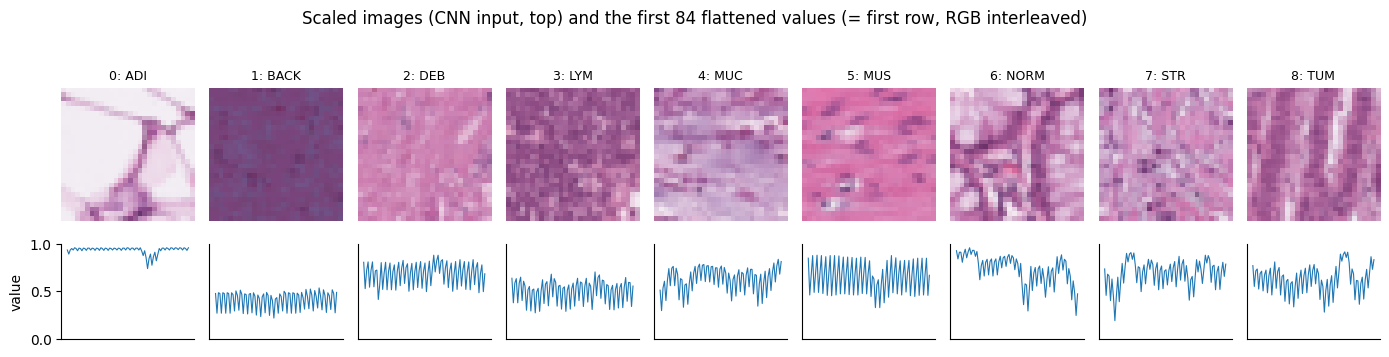

In [13]:
print(f"Image tensors (CNN):     X_fit_img {X_fit_img.shape} {X_fit_img.dtype}, "
      f"range [{X_fit_img.min():.1f}, {X_fit_img.max():.1f}]")
print(f"Flattened vectors (others): X_fit {X_fit.shape} {X_fit.dtype}")
print(f"Validation:              X_val_img {X_val_img.shape}, X_val {X_val.shape}")
example = 0
print(f"\nExample fit image #{example} (label {y_fit[example]} = {CLASS_NAMES[y_fit[example]]})")
print("Top-left 3x3 pixels, RGB channels after scaling:\n", np.round(X_fit_img[example, :3, :3, :], 3))
print("First 12 entries of the flattened vector:", np.round(X_fit[example, :12], 3))

fig, axes = plt.subplots(2, 9, figsize=(14, 3.6), gridspec_kw={"height_ratios": [2.2, 1]})
for k in range(NUM_CLASSES):
    i = int(np.flatnonzero(y_fit == k)[0])
    axes[0, k].imshow(X_fit_img[i]); axes[0, k].axis("off")
    axes[0, k].set_title(f"{k}: {SHORT_NAMES[k]}", fontsize=9)
    axes[1, k].plot(X_fit[i, :84], lw=0.8); axes[1, k].set_ylim(0, 1); axes[1, k].set_xticks([])
    if k: axes[1, k].set_yticks([])
axes[1, 0].set_ylabel("value")
fig.suptitle("Scaled images (CNN input, top) and the first 84 flattened values (= first row, RGB interleaved)")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "preprocessed_examples.png"); plt.show()

## 2. Algorithm design and setup

**Shared evaluation protocol.** All models are compared with three metrics computed by scikit-learn on the same partitions:
* **Macro-F1**: the unweighted mean of per-class F1 (harmonic mean of precision and recall). This is the primary metric, used for every selection decision.
* **Accuracy**: easy to interpret, but dominated by the larger classes.
* **Balanced accuracy**: the mean per-class recall.

We also record wall-clock fit time and prediction time (`time.perf_counter`), the number of learnable parameters, and per-epoch time for the networks.

In [14]:
def evaluate(y_true, y_pred):
    # The three headline metrics used everywhere in this notebook.
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=range(NUM_CLASSES), average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred)}

def fit_and_time(estimator, X_a, y_a, X_b):
    # Fit an sklearn estimator, predict, and time both stages separately.
    t0 = perf_counter(); estimator.fit(X_a, y_a); fit_s = perf_counter() - t0
    t0 = perf_counter(); pred = estimator.predict(X_b); pred_s = perf_counter() - t0
    return pred, fit_s, pred_s

### Reference baselines (not tuned)

Two deliberately simple models put the later results in context:
* **Dummy (most frequent)** ignores the image entirely. Any useful model must beat it, and its Macro-F1 (≈ 0.03) shows how strongly accuracy can be inflated by imbalance.
* **Nearest Centroid** assigns an image to the class whose mean image is closest in Euclidean distance. It is a one-prototype-per-class special case of the nearest-neighbour idea from the course. It has no hyperparameters in our use, so it is not tuned.

In [15]:
baseline_validation = []
for name, estimator in [("Dummy", DummyClassifier(strategy="most_frequent")),
                        ("Nearest Centroid", NearestCentroid())]:
    pred, fit_s, pred_s = fit_and_time(estimator, X_fit, y_fit, X_val)
    baseline_validation.append({"model": name, **evaluate(y_val, pred),
                                "fit_seconds": fit_s, "predict_seconds": pred_s})
baseline_validation = pd.DataFrame(baseline_validation).set_index("model")
display(baseline_validation.round(4))

,accuracy,macro_f1,balanced_accuracy,fit_seconds,predict_seconds
model,,,,,
Dummy,0.1467,0.0284,0.1111,0.0021,0.0001
Nearest Centroid,0.4222,0.4051,0.4237,0.1722,0.1155


### Algorithm of choice from first six weeks of course

**Gaussian Naive Bayes.** By Bayes' rule, the predicted class is $\hat y = \arg\max_k \; \log P(y{=}k) + \sum_{j=1}^{2352} \log \mathcal N(x_j;\, \mu_{kj}, \sigma^2_{kj}+\epsilon)$. Each feature is modelled as a class-conditional Gaussian, and the features are assumed **conditionally independent** given the class.

*Why GaussianNB rather than another weeks 1–6 method?*
1. It is a **generative, closed-form** model. Fitting is a single pass that computes means and variances, with no iterative optimisation. It therefore contrasts as much as possible with the two networks, which are discriminative and trained by gradient descent, and that contrast is the point of the comparison.
2. It scales linearly in samples and features: (32,000 × 2,352) fits in about a second. k-NN would need 32,000 × 8,000 distance computations at prediction time, and an RBF-SVM scales super-linearly with *n*.
3. It is interpretable: each class is summarised by a mean image and a variance image.
4. Its independence assumption is *known* to be violated here (finding 4). Measuring how much that costs is itself informative about the role of spatial dependence.

`var_smoothing` (ε) adds a fraction of the largest feature variance to every variance. This stabilises near-constant pixels (e.g. saturated background) and is the model's main hyperparameter. Below is an untuned instance with the scikit-learn default (ε = 1e-9).

In [16]:
gnb_initial = GaussianNB()
pred, fit_s, pred_s = fit_and_time(gnb_initial, X_fit, y_fit, X_val)
gnb_initial_scores = evaluate(y_val, pred)
print(f"Default GaussianNB (var_smoothing=1e-9): fit {fit_s:.3f}s, predict {pred_s:.3f}s ->",
      {k: round(v, 4) for k, v in gnb_initial_scores.items()})

Default GaussianNB (var_smoothing=1e-9): fit 0.602s, predict 1.628s -> {'accuracy': 0.4041, 'macro_f1': 0.3749, 'balanced_accuracy': 0.4188}


### Fully connected neural network

**Architecture:** `Input(2352) → Dense(h, ReLU) → Dropout(p) → Dense(9, softmax)`, trained with Adam on sparse categorical cross-entropy, batch size 128.

* Each dense unit computes a weighted sum of *all* 2,352 inputs followed by a ReLU. Unlike GaussianNB, the network can therefore learn arbitrary non-linear *combinations* of correlated pixels, and it makes no independence assumption.
* It has no notion of locality: weight $w_{ij}$ is tied to one absolute input position. A texture pattern shifted by one pixel activates entirely different weights, so the MLP has to learn every position separately (finding 3). This is the main expected weakness.
* We use **one hidden layer** on purpose. The first layer already holds $(2352+1)\,h$ parameters (≈ 300k–600k), so extra depth would mainly add parameters and CPU time without addressing the locality problem. A single layer also keeps the capacity comparison with the CNN easy to interpret.
* **Training control:** at most 12 epochs during tuning, with early stopping (patience 3) on **validation Macro-F1**, restoring the best epoch. We monitor Macro-F1 rather than validation loss because it is the selection metric, and cross-entropy can keep improving through more confident predictions on already-correct classes.

Macro-F1 is computed inside Keras by a small streaming metric (a 9×9 confusion matrix accumulated across batches). Averaging per-batch F1 values would be biased, because F1 is not additive. A unit test checks the metric against scikit-learn, including on batches where some classes are missing.

In [17]:
BATCH_SIZE = 128
MAX_TUNING_EPOCHS = 12
PATIENCE = 3

@keras.utils.register_keras_serializable(package="A2")
class StreamingMacroF1(keras.metrics.Metric):
    # Macro-F1 accumulated over a whole epoch from a confusion matrix (exact, not a batch average).
    def __init__(self, num_classes=NUM_CLASSES, name="macro_f1", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = int(num_classes)
        self.matrix = self.add_weight(name="confusion", shape=(self.num_classes, self.num_classes),
                                      initializer="zeros", dtype="float32")

    def update_state(self, y_true, y_pred, sample_weight=None):
        actual = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        predicted = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        self.matrix.assign_add(tf.math.confusion_matrix(actual, predicted, num_classes=self.num_classes,
                                                        dtype=tf.float32))

    def result(self):
        tp = tf.linalg.diag_part(self.matrix)
        denom = tf.reduce_sum(self.matrix, axis=0) + tf.reduce_sum(self.matrix, axis=1)
        return tf.reduce_mean(tf.math.divide_no_nan(2.0 * tp, denom))

    def reset_state(self):
        self.matrix.assign(tf.zeros_like(self.matrix))

    def get_config(self):
        return {**super().get_config(), "num_classes": self.num_classes}


def make_dataset(features, targets=None, training=False):
    # Deterministic tf.data pipeline: seeded shuffle, fixed batch order, single-threaded map.
    data = tf.data.Dataset.from_tensor_slices(features if targets is None else (features, targets))
    if training:
        data = data.shuffle(len(features), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 1
    return data.batch(BATCH_SIZE).with_options(options).prefetch(1)


class EpochLogger(keras.callbacks.Callback):
    # Logs metrics per epoch and separates training time from in-fit validation time.
    def __init__(self):
        super().__init__()
        self.records = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0, self._val_s = perf_counter(), 0.0

    def on_test_begin(self, logs=None):
        self._v0 = perf_counter()

    def on_test_end(self, logs=None):
        self._val_s += perf_counter() - self._v0

    def on_epoch_end(self, epoch, logs=None):
        total = perf_counter() - self._t0
        values = {k: float(v) for k, v in (logs or {}).items()}
        if not all(np.isfinite(list(values.values()))):
            raise FloatingPointError("non-finite metric")
        self.records.append({"epoch": epoch + 1, **values, "epoch_seconds": total,
                             "train_seconds": total - self._val_s, "val_seconds": self._val_s})


def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"), StreamingMacroF1()],
                  jit_compile=False)
    return model


def build_mlp(hidden_units, learning_rate, dropout_rate):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)           # identical initial weights for every trial
    model = keras.Sequential([
        keras.Input(shape=(2352,)),
        keras.layers.Dense(hidden_units, activation="relu"),
        keras.layers.Dropout(dropout_rate, seed=SEED),
        keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="mlp")
    assert model.count_params() == (2352 + 1) * hidden_units + (hidden_units + 1) * NUM_CLASSES
    return compile_model(model, learning_rate)


def fit_development(build_fn, params, X_a, X_b, max_epochs=MAX_TUNING_EPOCHS):
    # Train on the fit partition with early stopping on validation Macro-F1 (best epoch restored).
    model = build_fn(**params)
    logger = EpochLogger()
    stopper = keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=PATIENCE,
                                            restore_best_weights=True)
    t0 = perf_counter()
    history = model.fit(make_dataset(X_a, y_fit, training=True),
                        validation_data=make_dataset(X_b, y_val), epochs=max_epochs,
                        callbacks=[logger, stopper, keras.callbacks.TerminateOnNaN()], verbose=0)
    fit_s = perf_counter() - t0
    t0 = perf_counter()
    pred = model.predict(make_dataset(X_b), verbose=0).argmax(axis=1)
    pred_s = perf_counter() - t0
    scores = evaluate(y_val, pred)
    # The restored weights must reproduce the best epoch's streaming metric exactly.
    assert np.isclose(scores["macro_f1"], max(history.history["val_macro_f1"]), atol=2e-6)
    result = {**params, **{f"val_{k}": v for k, v in scores.items()},
              "best_epoch": int(np.argmax(history.history["val_macro_f1"]) + 1),
              "epochs_run": len(logger.records), "fit_seconds": fit_s, "val_predict_seconds": pred_s,
              "mean_epoch_train_seconds": float(np.mean([r["train_seconds"] for r in logger.records])),
              "parameters": int(model.count_params())}
    return model, pd.DataFrame(logger.records), result


# Unit test: streaming metric == sklearn macro-F1, including classes absent from a batch.
check_true, check_pred = np.array([0, 0, 1, 1, 2]), np.array([0, 1, 1, 1, 0])
metric = StreamingMacroF1()
for part in (slice(0, 2), slice(2, None)):
    metric.update_state(check_true[part], tf.one_hot(check_pred[part], NUM_CLASSES))
assert np.isclose(float(metric.result()), evaluate(check_true, check_pred)["macro_f1"], atol=1e-6)
print("Streaming Macro-F1 matches scikit-learn.")

mlp_preview = build_mlp(hidden_units=128, learning_rate=1e-3, dropout_rate=0.0)   # untuned instance
mlp_preview.summary()
del mlp_preview

Streaming Macro-F1 matches scikit-learn.


Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       301,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,345 (1.15 MB)

 Trainable params: 302,345 (1.15 MB)

 Non-trainable params: 0 (0.00 B)

### Convolutional neural network

**Architecture** (built from basic Keras layers):

`Input(28,28,3) → Conv(f, 3×3, same, ReLU) → MaxPool 2×2 → Conv(2f, 3×3, same, ReLU) → MaxPool 2×2 → Flatten → Dense(64, ReLU) → Dropout(p) → Dense(9, softmax)`

* **Local receptive fields and weight sharing.** A 3×3 filter looks at a small neighbourhood (where we found pixel correlation concentrated, finding 4) and is reused at every position. A texture is therefore detected wherever it occurs (translation *equivariance*, finding 3). With $f=16$, the first layer has only $3·3·3·16 + 16 = 448$ parameters, compared with ≈ 300k–600k for the MLP's first layer.
* **Two blocks.** The receptive field grows from 3×3 to 8×8 input pixels after the second convolution (10×10 after the second pooling), which is enough to cover small glandular and nuclear structures in a 28-pixel patch. 2×2 max-pooling halves the resolution (28→14→7), adds some local shift *invariance*, and cuts computation in later layers.
* **Doubling the filters (f → 2f)** compensates for the lost resolution with richer feature channels. This is a standard pattern that keeps per-layer computation roughly balanced.
* **Dense(64) head.** Flattening the 7×7×2f maps keeps the coarse layout. About 95 % of the parameters sit in this layer, so the CNN is *not* small simply because it is convolutional (see the parameter breakdown below).
* Same optimiser, loss, batch size, early-stopping rule and metric as the MLP, so the comparison changes only the inductive bias.

In [18]:
def build_cnn(base_filters, learning_rate, dropout_rate):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 3)),
        keras.layers.Conv2D(base_filters, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Conv2D(2 * base_filters, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout_rate, seed=SEED),
        keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="cnn")
    return compile_model(model, learning_rate)

cnn_preview = build_cnn(base_filters=16, learning_rate=1e-3, dropout_rate=0.3)    # untuned instance
cnn_preview.summary()
param_breakdown = pd.DataFrame([{"layer": layer.name, "parameters": layer.count_params()}
                                for layer in cnn_preview.layers if layer.count_params()])
param_breakdown["share_%"] = 100 * param_breakdown["parameters"] / param_breakdown["parameters"].sum()
display(param_breakdown.round(1))
del cnn_preview

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,089 (414.41 KB)

 Trainable params: 106,089 (414.41 KB)

 Non-trainable params: 0 (0.00 B)

,layer,parameters,share_%
0,conv2d,448,0.4
1,conv2d_1,4640,4.4
2,dense,100416,94.7
3,dense_1,585,0.6


## 3. Hyperparameter tuning

**Search method.** A full-factorial **grid search on the fixed validation split** (Section 1.2), selecting by validation Macro-F1. Ties are broken first by fewer parameters, then by the earlier trial. A grid rather than a random or Bayesian search was chosen because:
1. With 2 values for each of 3 hyperparameters (8 trials), a full factorial lets us read off **main effects and interactions**. That is the analysis the report needs, and random search would not give a balanced design.
2. Each value pair is chosen to straddle a plausible regime boundary (see the tables below), so the grid tests a hypothesis rather than fine-tuning a number.
3. The full search (≈ 12.5 minutes for both networks on our 2-core CPU) fits our hardware budget. Each trial uses all 25,600 fit images rather than a subsample.

Every trial starts from the same seeded initial weights and data order, so differences between trials come from the hyperparameters and not from random draws. Runtime is recorded for each trial. All searches use **only** the fit and validation partitions.

*The cells below run only when `RUN_TUNING` is true. Their outputs are preserved from the full run, and every result is also written to `results/search_*.csv`, which the analysis cells reload when the searches are skipped.*

### Reference baselines
No search is performed: Dummy has no relevant hyperparameter, and Nearest Centroid is used in its parameter-free form. They are fixed reference points.

### Algorithm of choice from first six weeks of course

`var_smoothing` ∈ {1e-12, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 0.1, 1} (log grid).

**Prediction.** After scaling, the largest per-pixel variance is ≈ 0.03 (the smallest ≈ 0.015), so the added variance is ε × 0.03. For ε ≪ 0.01 this is negligible next to the real variances, and we expect a **flat plateau**. Once ε × 0.03 becomes comparable to the feature variances (ε ≥ 0.1), the class-specific variance differences are swamped. Every class then behaves like a common-variance Gaussian (close to Nearest Centroid), and Macro-F1 should fall. GaussianNB has no other continuous hyperparameter. We kept the empirical class priors, because the imbalance is mild (≈ 1.7) and the priors' effect is dwarfed by a likelihood summed over 2,352 features.

In [19]:
GNB_GRID = [1e-12, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1e-1, 1.0]
if RUN_TUNING:
    print(f"Largest / smallest per-feature variance in the fit partition: "
          f"{X_fit.var(axis=0).max():.4f} / {X_fit.var(axis=0).min():.4f}")
    records = []
    for eps in GNB_GRID:
        pred, fit_s, pred_s = fit_and_time(GaussianNB(var_smoothing=eps), X_fit, y_fit, X_val)
        records.append({"var_smoothing": eps, **{f"val_{k}": v for k, v in evaluate(y_val, pred).items()},
                        "fit_seconds": fit_s, "val_predict_seconds": pred_s})
    gnb_search = pd.DataFrame(records)
    gnb_search.to_csv(RESULTS_DIR / "search_gnb.csv", index=False)
    display(gnb_search.style.format({"var_smoothing": "{:.0e}", **{c: "{:.4f}" for c in gnb_search.columns[1:]}}))
else:
    print("GaussianNB search skipped (RUN_TUNING is False).")

Largest / smallest per-feature variance in the fit partition: 0.0337 / 0.0154


,var_smoothing,val_accuracy,val_macro_f1,val_balanced_accuracy,fit_seconds,val_predict_seconds
0,1e-12,0.4041,0.3749,0.4188,0.5539,1.5025
1,1e-10,0.4041,0.3749,0.4188,0.6809,1.3219
2,1e-08,0.4041,0.3749,0.4188,0.5478,1.3616
3,1e-06,0.4041,0.3749,0.4188,0.6535,1.4017
4,1e-04,0.4039,0.3748,0.4186,0.5547,1.5480
5,1e-02,0.4028,0.3719,0.4172,0.5568,1.5368
6,1e-01,0.4027,0.3597,0.4161,0.5654,1.3925
7,1e+00,0.3345,0.2664,0.3494,0.6034,1.3277


Best validation Macro-F1 0.3749, shared by var_smoothing in ['1e-12', '1e-10', '1e-08', '1e-06']


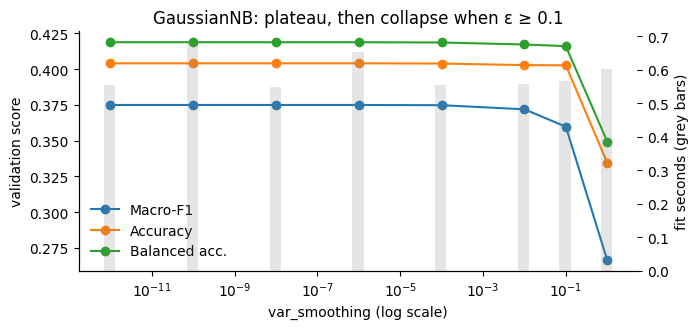

In [20]:
# Analysis: reload the search table if the search cell above was skipped.
gnb_search = globals().get("gnb_search")
if gnb_search is None and (RESULTS_DIR / "search_gnb.csv").exists():
    gnb_search = pd.read_csv(RESULTS_DIR / "search_gnb.csv")
if gnb_search is not None:
    best = gnb_search.sort_values(["val_macro_f1", "var_smoothing"], ascending=[False, False]).iloc[0]
    plateau = gnb_search[np.isclose(gnb_search["val_macro_f1"], gnb_search["val_macro_f1"].max(), atol=1e-9)]
    print(f"Best validation Macro-F1 {best['val_macro_f1']:.4f}, shared by var_smoothing in "
          f"{[f'{v:.0e}' for v in plateau['var_smoothing']]}")
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for col, label in [("val_macro_f1", "Macro-F1"), ("val_accuracy", "Accuracy"),
                       ("val_balanced_accuracy", "Balanced acc.")]:
        ax.plot(gnb_search["var_smoothing"], gnb_search[col], marker="o", label=label)
    ax.set_xscale("log"); ax.set_xlabel("var_smoothing (log scale)"); ax.set_ylabel("validation score")
    ax2 = ax.twinx()
    ax2.bar(gnb_search["var_smoothing"], gnb_search["fit_seconds"], width=gnb_search["var_smoothing"] * 0.6,
            alpha=0.2, color="grey"); ax2.set_ylabel("fit seconds (grey bars)")
    ax.legend(frameon=False, loc="lower left"); ax.set_title("GaussianNB: plateau, then collapse when ε ≥ 0.1")
    fig.tight_layout(); fig.savefig(RESULTS_DIR / "search_gnb.png"); plt.show()
else:
    print("No GaussianNB search results available.")

**Interpretation.** The plateau is exactly as predicted: ε from 1e-12 to 1e-6 gives *identical* predictions. The scores start to slip at 1e-4 to 1e-2 and drop sharply at ε = 1, where the added variance (≈ 0.034) is as large as the largest per-pixel variance and twice the smallest. Fit time (under a second) does not depend on ε, because ε is added after the variances are computed, so the runtime differences are timing noise. Because the top values tie exactly, we take **ε = 1e-6** as a principled tie-break: it is the largest value on the plateau that is still at least four orders of magnitude below every feature variance. It therefore stabilises near-constant pixels without changing the model. This choice was fixed before any test evaluation.

**Critical note.** The flat plateau tells us that *tuning cannot rescue GaussianNB here*. Its error comes from the model's assumptions (independent features), not from regularisation. Validation Macro-F1 ≈ 0.375 is *below* the parameter-free Nearest Centroid (≈ 0.41). Modelling each class with per-pixel variances, which is GaussianNB's extra flexibility, therefore does harm on these data. The likely reason is that 2,352 highly correlated log-likelihood terms are added as if they were independent evidence. Small systematic variance mismatches are then multiplied thousands of times, and the posterior becomes extremely over-confident. This motivates the PCA-decorrelation idea under *Future work* at the end of Section 4.

### Fully connected neural network

| Hyperparameter | Values | What it controls and what we expect |
|---|---|---|
| Hidden units *h* | 128, 256 | Capacity and parameter count (302k vs 605k). More units should fit the non-linear pixel combinations better, at about twice the time per epoch. With 25k images, overfitting is possible but unlikely to dominate within 12 epochs. |
| Adam learning rate | 1e-3, 3e-4 | Step size. 1e-3 converges faster within the 12-epoch budget. 3e-4 is steadier but may need more epochs than the budget allows. With 2,352 un-standardised inputs, too large a step can push ReLUs into the dead zone. |
| Dropout *p* | 0.0, 0.3 | Randomly zeroes hidden activations during training (regularisation and implicit ensembling). It helps when the model overfits, but slows fitting and can cause underfitting in a single small layer trained for few epochs. |

Fixed: depth (1 hidden layer), ReLU, Adam, batch 128, ≤ 12 epochs, patience 3. Our prediction was that the larger width would help and that dropout would be of little benefit, since we did not expect an MLP this small to overfit in 12 epochs.

In [21]:
MLP_GRID = list(product([128, 256], [1e-3, 3e-4], [0.0, 0.3]))   # (hidden_units, learning_rate, dropout)
if RUN_TUNING:
    mlp_rows, mlp_curves = [], []
    t_search = perf_counter()
    for trial, (h, lr, p) in enumerate(MLP_GRID, start=1):
        params = {"hidden_units": h, "learning_rate": lr, "dropout_rate": p}
        model, curve, result = fit_development(build_mlp, params, X_fit, X_val)
        mlp_rows.append({"trial": trial, **result})
        mlp_curves.append(curve.assign(trial=trial))
        print(f"trial {trial}: h={h:<3} lr={lr:<6} p={p:<3} -> val Macro-F1 {result['val_macro_f1']:.4f} "
              f"(best epoch {result['best_epoch']}/{result['epochs_run']}, {result['fit_seconds']:.1f}s)")
        del model; gc.collect()
    mlp_search_seconds = perf_counter() - t_search
    mlp_search = pd.DataFrame(mlp_rows)
    mlp_curves = pd.concat(mlp_curves, ignore_index=True)
    mlp_search.to_csv(RESULTS_DIR / "search_mlp.csv", index=False)
    mlp_curves.to_csv(RESULTS_DIR / "search_mlp_curves.csv", index=False)
    print(f"\nTotal MLP search wall time: {mlp_search_seconds:.1f} s")
else:
    print("MLP search skipped (RUN_TUNING is False).")

trial 1: h=128 lr=0.001  p=0.0 -> val Macro-F1 0.3845 (best epoch 5/8, 19.1s)


trial 2: h=128 lr=0.001  p=0.3 -> val Macro-F1 0.0341 (best epoch 3/6, 15.5s)


trial 3: h=128 lr=0.0003 p=0.0 -> val Macro-F1 0.4038 (best epoch 9/12, 23.4s)


trial 4: h=128 lr=0.0003 p=0.3 -> val Macro-F1 0.3370 (best epoch 11/12, 24.7s)


trial 5: h=256 lr=0.001  p=0.0 -> val Macro-F1 0.4277 (best epoch 9/12, 36.1s)


trial 6: h=256 lr=0.001  p=0.3 -> val Macro-F1 0.3407 (best epoch 4/7, 21.7s)


trial 7: h=256 lr=0.0003 p=0.0 -> val Macro-F1 0.4060 (best epoch 10/12, 38.3s)


trial 8: h=256 lr=0.0003 p=0.3 -> val Macro-F1 0.3578 (best epoch 7/10, 27.6s)

Total MLP search wall time: 216.8 s


,trial,hidden_units,learning_rate,dropout_rate,val_macro_f1,val_accuracy,val_balanced_accuracy,best_epoch,epochs_run,fit_seconds,mean_epoch_train_seconds,parameters
4,5,256,0.0010,0.0,0.4277,0.4458,0.4483,9,12,36.1344,2.6816,604681
6,7,256,0.0003,0.0,0.4060,0.4289,0.4405,10,12,38.2760,2.8796,604681
2,3,128,0.0003,0.0,0.4038,0.4392,0.4309,9,12,23.3513,1.7121,302345
0,1,128,0.0010,0.0,0.3845,0.4281,0.4178,5,8,19.1098,1.9875,302345
7,8,256,0.0003,0.3,0.3578,0.4169,0.3995,7,10,27.5529,2.4693,604681
5,6,256,0.0010,0.3,0.3407,0.3797,0.3664,4,7,21.7223,2.7464,604681
3,4,128,0.0003,0.3,0.3370,0.4120,0.3901,11,12,24.7122,1.8086,302345
1,2,128,0.0010,0.3,0.0341,0.1495,0.1140,3,6,15.4868,2.2643,302345


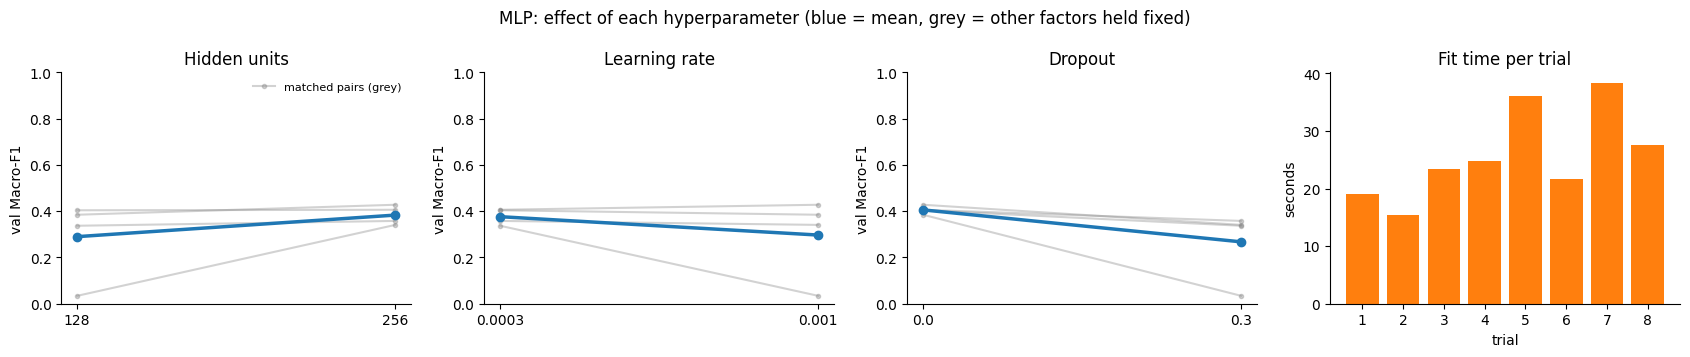

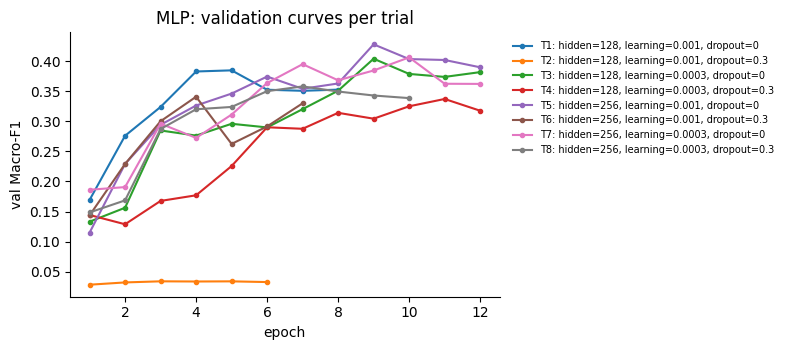

mean val Macro-F1 by hidden_units: {128: 0.2899, 256: 0.3831}
mean val Macro-F1 by learning_rate: {0.0003: 0.3762, 0.001: 0.2968}
mean val Macro-F1 by dropout_rate: {0.0: 0.4055, 0.3: 0.2674}


In [22]:
def load_search(name):
    # Use in-memory search results if the search ran in this session, else the saved CSVs.
    table, curves = globals().get(f"{name}_search"), globals().get(f"{name}_curves")
    if table is None and (RESULTS_DIR / f"search_{name}.csv").exists():
        table = pd.read_csv(RESULTS_DIR / f"search_{name}.csv")
        curves = pd.read_csv(RESULTS_DIR / f"search_{name}_curves.csv")
    return table, curves

def rank_trials(table):
    return table.sort_values(["val_macro_f1", "parameters", "trial"], ascending=[False, True, True])

def plot_search(table, curves, hp_cols, labels, tag):
    # Main effects (mean over the other factors) + interaction lines, runtime, and validation curves.
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, col, label in zip(axes[:3], hp_cols, labels):
        others = [c for c in hp_cols if c != col]
        for _, grp in table.groupby(others):
            g = grp.sort_values(col)
            ax.plot(g[col].astype(str), g["val_macro_f1"], color="grey", alpha=0.35, marker=".")
        means = table.groupby(col)["val_macro_f1"].mean()
        ax.plot(means.index.astype(str), means.values, color="tab:blue", lw=2.5, marker="o", label="mean")
        ax.set_title(f"{label}"); ax.set_ylabel("val Macro-F1"); ax.set_ylim(0, 1)
    axes[0].legend(["matched pairs (grey)"], frameon=False, fontsize=8)
    order = table.sort_values("trial")
    axes[3].bar(order["trial"].astype(str), order["fit_seconds"], color="tab:orange")
    axes[3].set_title("Fit time per trial"); axes[3].set_xlabel("trial"); axes[3].set_ylabel("seconds")
    fig.suptitle(f"{tag}: effect of each hyperparameter (blue = mean, grey = other factors held fixed)")
    fig.tight_layout(); fig.savefig(RESULTS_DIR / f"search_{tag.lower()}_effects.png"); plt.show()

    fig, ax = plt.subplots(figsize=(8, 3.6))
    for trial, grp in curves.groupby("trial"):
        row = table.set_index("trial").loc[trial]
        lbl = ", ".join(f"{c.split('_')[0]}={row[c]:g}" for c in hp_cols)
        ax.plot(grp["epoch"], grp["val_macro_f1"], marker=".", label=f"T{trial}: {lbl}")
    ax.set_xlabel("epoch"); ax.set_ylabel("val Macro-F1"); ax.set_title(f"{tag}: validation curves per trial")
    ax.legend(fontsize=7, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout(); fig.savefig(RESULTS_DIR / f"search_{tag.lower()}_curves.png", bbox_inches="tight"); plt.show()

mlp_search, mlp_curves = load_search("mlp")
if mlp_search is not None:
    cols = ["trial", "hidden_units", "learning_rate", "dropout_rate", "val_macro_f1", "val_accuracy",
            "val_balanced_accuracy", "best_epoch", "epochs_run", "fit_seconds", "mean_epoch_train_seconds",
            "parameters"]
    display(rank_trials(mlp_search)[cols].round(4))
    plot_search(mlp_search, mlp_curves, ["hidden_units", "learning_rate", "dropout_rate"],
                ["Hidden units", "Learning rate", "Dropout"], "MLP")
    for col in ["hidden_units", "learning_rate", "dropout_rate"]:
        print(f"mean val Macro-F1 by {col}:", mlp_search.groupby(col)["val_macro_f1"].mean().round(4).to_dict())
else:
    print("No MLP search results available.")

**Interpretation of the MLP search.**

* **Selected: 256 units, learning rate 1e-3, no dropout** (trial 5, validation Macro-F1 0.428 at epoch 9). It is the same configuration selected in every earlier execution of this search.
* **Width helped in all four matched pairs** (mean 0.383 vs 0.290), as predicted. The time per epoch rose only ≈ 1.4× on average (1.2–1.7× across matched pairs), not 2×, because a fixed share of each epoch goes to the input pipeline and the in-fit validation pass.
* **Dropout hurt in all four matched pairs** (mean 0.267 vs 0.406). This is stronger than our "little benefit" prediction. A single 256-unit layer trained for at most 12 epochs is *underfitting*, not overfitting: training and validation loss fall together and stay almost equal (1.508 vs 1.509 at the best epoch). Adding noise to an underfitting model only slows it further [Srivastava et al. 2014].
* **The learning-rate effect reverses depending on the other factors.** On average 3e-4 looks better (0.376 vs 0.297), but the best model uses 1e-3. The average is distorted by **trial 2** (128 units, 1e-3, dropout 0.3), which collapsed to Macro-F1 0.034 and accuracy ≈ 0.15. Its training loss stayed at ≈ 2.18, close to ln 9 ≈ 2.20, meaning it predicted almost the same class for every image, and early stopping ended the trial after 6 epochs. We kept this trial rather than discarding it as a "bug", because it reproduced identically on every machine. The likely mechanism: all inputs are positive and un-centred, so a large early Adam step combined with dropout noise can push most of the 128 ReLUs into their zero region ("dying ReLU"), from which they get no gradient. The lower learning rate and the wider layer are both more robust to this. Centring the inputs, He initialisation checks, or batch normalisation are the obvious fixes; we did not test them, so this explanation remains a hypothesis.
* **Absolute performance is low** (validation Macro-F1 ≤ 0.43, barely above the parameter-free Nearest Centroid at 0.405) despite 605k parameters. This supports our prior concern: without a spatial prior, the MLP spends its capacity re-learning the same texture at every position.
* **Runtime:** the eight trials took ≈ 3.6 minutes in total (≈ 15–38 s each). The differences are driven mostly by the number of epochs run before early stopping, then by width.

### Convolutional neural network

| Hyperparameter | Values | What it controls and what we expect |
|---|---|---|
| Base filters *f* (2nd layer = 2*f*) | 8, 16 | Number of distinct local patterns each layer can detect, and parameter count (52k vs 106k). The convolutional cost grows roughly quadratically in *f*. We expect 16 to help, because 9 tissue textures probably need more than 8 first-layer detectors. |
| Adam learning rate | 1e-3, 3e-4 | As for the MLP. CNN loss surfaces are smoother (fewer, shared weights), so 1e-3 should be safe and faster. |
| Dropout *p* in the dense head | 0.0, 0.3 | Regularises the 64-unit head, where about 95 % of the parameters sit. The CNN learns faster than the MLP and is more likely to start overfitting within 12 epochs, so dropout is more likely to help here. |

Fixed: kernel 3×3 with `same` padding, two conv blocks, 2×2 max-pooling, Dense(64), Adam, batch 128, ≤ 12 epochs, patience 3. We kept the filter count as the capacity hyperparameter rather than kernel size or stride. With 28×28 inputs, larger kernels or stride 2 would discard fine texture that the EDA suggests matters.

In [23]:
CNN_GRID = list(product([8, 16], [1e-3, 3e-4], [0.0, 0.3]))   # (base_filters, learning_rate, dropout)
if RUN_TUNING:
    cnn_rows, cnn_curves = [], []
    t_search = perf_counter()
    for trial, (f, lr, p) in enumerate(CNN_GRID, start=1):
        params = {"base_filters": f, "learning_rate": lr, "dropout_rate": p}
        model, curve, result = fit_development(build_cnn, params, X_fit_img, X_val_img)
        cnn_rows.append({"trial": trial, **result})
        cnn_curves.append(curve.assign(trial=trial))
        print(f"trial {trial}: f={f:<2} lr={lr:<6} p={p:<3} -> val Macro-F1 {result['val_macro_f1']:.4f} "
              f"(best epoch {result['best_epoch']}/{result['epochs_run']}, {result['fit_seconds']:.1f}s)")
        del model; gc.collect()
    cnn_search_seconds = perf_counter() - t_search
    cnn_search = pd.DataFrame(cnn_rows)
    cnn_curves = pd.concat(cnn_curves, ignore_index=True)
    cnn_search.to_csv(RESULTS_DIR / "search_cnn.csv", index=False)
    cnn_curves.to_csv(RESULTS_DIR / "search_cnn_curves.csv", index=False)
    print(f"\nTotal CNN search wall time: {cnn_search_seconds:.1f} s")
else:
    print("CNN search skipped (RUN_TUNING is False).")

trial 1: f=8  lr=0.001  p=0.0 -> val Macro-F1 0.7068 (best epoch 12/12, 50.4s)


trial 2: f=8  lr=0.001  p=0.3 -> val Macro-F1 0.7064 (best epoch 12/12, 49.2s)


trial 3: f=8  lr=0.0003 p=0.0 -> val Macro-F1 0.6725 (best epoch 12/12, 55.2s)


trial 4: f=8  lr=0.0003 p=0.3 -> val Macro-F1 0.6602 (best epoch 12/12, 48.0s)


trial 5: f=16 lr=0.001  p=0.0 -> val Macro-F1 0.7204 (best epoch 7/10, 55.9s)


trial 6: f=16 lr=0.001  p=0.3 -> val Macro-F1 0.7276 (best epoch 11/12, 77.9s)


trial 7: f=16 lr=0.0003 p=0.0 -> val Macro-F1 0.7004 (best epoch 12/12, 95.8s)


trial 8: f=16 lr=0.0003 p=0.3 -> val Macro-F1 0.6953 (best epoch 12/12, 86.1s)

Total CNN search wall time: 534.7 s


,trial,base_filters,learning_rate,dropout_rate,val_macro_f1,val_accuracy,val_balanced_accuracy,best_epoch,epochs_run,fit_seconds,mean_epoch_train_seconds,parameters
5,6,16,0.0010,0.3,0.7276,0.7409,0.7318,11,12,77.9292,5.8735,106089
4,5,16,0.0010,0.0,0.7204,0.7281,0.7187,7,10,55.8747,4.9385,106089
0,1,8,0.0010,0.0,0.7068,0.7222,0.7084,12,12,50.4367,3.7734,52217
1,2,8,0.0010,0.3,0.7064,0.7181,0.7096,12,12,49.2276,3.5396,52217
6,7,16,0.0003,0.0,0.7004,0.7181,0.7046,12,12,95.7975,6.9302,106089
7,8,16,0.0003,0.3,0.6953,0.7098,0.6997,12,12,86.1208,6.5585,106089
2,3,8,0.0003,0.0,0.6725,0.6872,0.6767,12,12,55.1597,4.0108,52217
3,4,8,0.0003,0.3,0.6602,0.6803,0.6679,12,12,47.9532,3.5330,52217


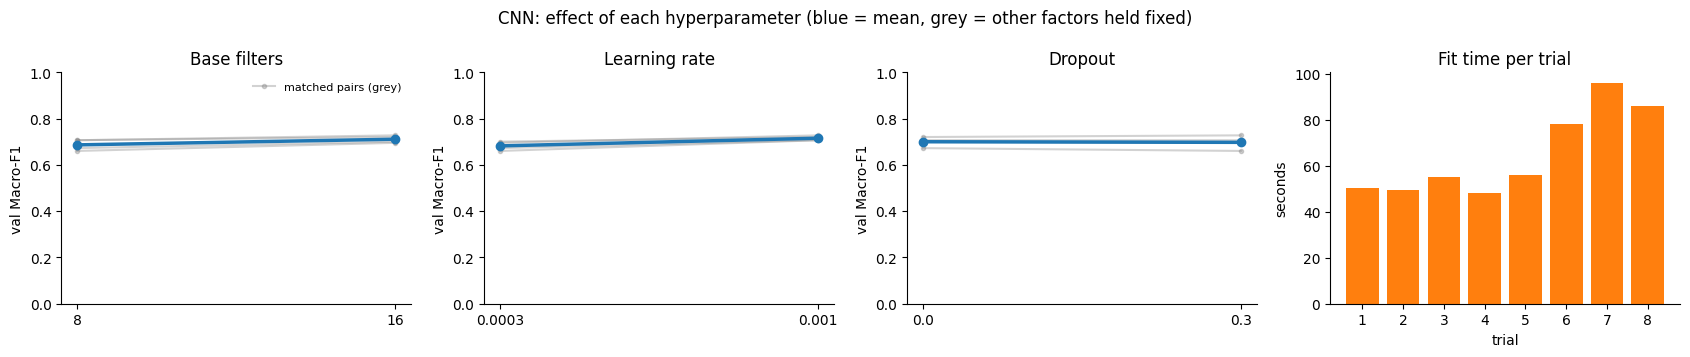

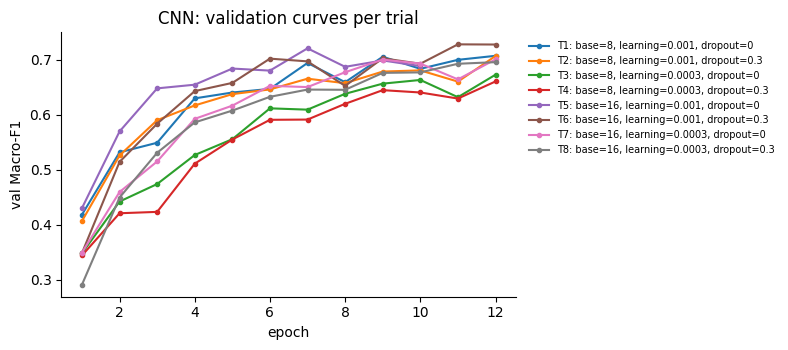

mean val Macro-F1 by base_filters: {8: 0.6865, 16: 0.7109}
mean val Macro-F1 by learning_rate: {0.0003: 0.6821, 0.001: 0.7153}
mean val Macro-F1 by dropout_rate: {0.0: 0.7, 0.3: 0.6974}


In [24]:
cnn_search, cnn_curves = load_search("cnn")
if cnn_search is not None:
    cols = ["trial", "base_filters", "learning_rate", "dropout_rate", "val_macro_f1", "val_accuracy",
            "val_balanced_accuracy", "best_epoch", "epochs_run", "fit_seconds", "mean_epoch_train_seconds",
            "parameters"]
    display(rank_trials(cnn_search)[cols].round(4))
    plot_search(cnn_search, cnn_curves, ["base_filters", "learning_rate", "dropout_rate"],
                ["Base filters", "Learning rate", "Dropout"], "CNN")
    for col in ["base_filters", "learning_rate", "dropout_rate"]:
        print(f"mean val Macro-F1 by {col}:", cnn_search.groupby(col)["val_macro_f1"].mean().round(4).to_dict())
else:
    print("No CNN search results available.")

**Interpretation of the CNN search.**

* **Selected: 16 base filters, learning rate 1e-3, dropout 0.3** (trial 6, validation Macro-F1 0.728 at epoch 11). Again, it is the same configuration selected in every earlier execution.
* **16 filters beat 8 in all four matched pairs** (mean 0.711 vs 0.687). The parameter count doubles (52k → 106k), but almost all of the extra parameters sit in the dense head. The time per epoch rises ≈ 1.3–1.9× because the convolutions' FLOPs scale with the number of filters. As predicted, eight first-layer detectors are too few for nine tissue textures.
* **1e-3 beats 3e-4 in all four matched pairs** (mean 0.715 vs 0.682). Six of the eight trials reached their best epoch at the 12-epoch cap, including **every** 3e-4 trial. Those models were still improving, so the comparison partly measures *speed of convergence within our budget* rather than final quality. This is a limitation of the fixed budget, which was set for runtime reasons.
* **Dropout matters only for the strongest configuration.** It is roughly neutral or slightly harmful for 8 filters and for the slow learning rate. For 16 filters at 1e-3 it helped (0.728 vs 0.720), and the dropout-free trial 5 peaked at epoch 7 and then early-stopped at epoch 10. This is consistent with our prediction that the CNN, unlike the MLP, learns fast enough to begin overfitting within 12 epochs, so regularising its dense head pays off there. The gain (0.007) is within the cross-platform noise discussed in Section 4, so we treat it as a weak preference rather than a firm effect.
* **The CNN dominates the MLP at a fraction of the parameters:** the *worst* CNN trial (0.660) beats the *best* MLP trial (0.428) by 0.23 Macro-F1 with ≈ 6–12× fewer parameters. This is the clearest evidence in the study that inductive bias, not capacity, is what matters on this data.
* **Runtime:** the eight trials took ≈ 9 minutes in total (≈ 48–96 s each). The per-epoch cost is ≈ 2× that of the MLP trials on average despite far fewer parameters, because convolution reuses each weight at 784 or 196 positions and so performs more multiply-adds per image.

### Selected configurations and the epoch budget

The final models are retrained on all 32,000 training images (Section 4). With no validation set left, early stopping is not available, so we transfer a **fixed epoch count** from the search. The cell below examines how sensitive that choice is, by reading the validation curve of each selected configuration around its best epoch.

In [25]:
selection_rows = []
for tag, table, curves, hp in [("MLP", mlp_search, mlp_curves, ["hidden_units", "learning_rate", "dropout_rate"]),
                               ("CNN", cnn_search, cnn_curves, ["base_filters", "learning_rate", "dropout_rate"])]:
    if table is None:
        continue
    best = rank_trials(table).iloc[0]
    curve = curves[curves["trial"] == best["trial"]].set_index("epoch")["val_macro_f1"]
    e = int(best["best_epoch"])
    neighbourhood = curve.loc[max(1, e - 2): e + 2]
    selection_rows.append({"model": tag, **{c: best[c] for c in hp}, "trial": int(best["trial"]),
                           "val_macro_f1": best["val_macro_f1"], "best_epoch_this_run": e,
                           "val_F1_range_within_±2_epochs": float(neighbourhood.max() - neighbourhood.min())})
    print(f"{tag} validation Macro-F1 by epoch around the best epoch:",
          {int(k): round(v, 4) for k, v in neighbourhood.items()})
if selection_rows:
    display(pd.DataFrame(selection_rows).round(4))

MLP validation Macro-F1 by epoch around the best epoch: {7: 0.3539, 8: 0.3627, 9: 0.4277, 10: 0.4033, 11: 0.4018}
CNN validation Macro-F1 by epoch around the best epoch: {9: 0.7024, 10: 0.6924, 11: 0.7276, 12: 0.7273}


,model,hidden_units,learning_rate,dropout_rate,trial,val_macro_f1,best_epoch_this_run,val_F1_range_within_±2_epochs,base_filters
0,MLP,256.0,0.001,0.0,5,0.4277,9,0.0738,NaN
1,CNN,NaN,0.001,0.3,6,0.7276,11,0.0352,16.0


**Epoch budget, and a reproducibility finding.** The searches were first run during development on the group members' own laptops: the MLP on a Windows/Intel machine, and the CNN on macOS/Apple Silicon. Those runs selected **exactly the configurations shown above**, with best epochs of **10 (MLP)** and **11 (CNN)**, and we froze those epoch counts *before* the first test-set evaluation. When we re-executed the identical searches with the pinned stack on other CPUs, the selected configurations never changed, but the arg-max epoch did:

| Search executed on | MLP best epoch | CNN best epoch |
|---|---|---|
| Development laptops (Windows/Intel; macOS/arm64) | 10 | 11 |
| Docker, AMD Ryzen 9 5900HS | 9 | 12 |
| This notebook run (Intel Xeon, AVX-512) | 9 | 11 |

The epoch curves printed above explain why. Validation Macro-F1 does **not** sit on a smooth plateau: it oscillates by several points from one epoch to the next. For the MLP this run gives 0.354 → 0.363 → **0.428** → 0.403 over epochs 7–10. For the CNN it gives 0.702 → 0.692 → **0.728** → 0.727 over epochs 9–12. With a constant learning rate and no averaging, the arg-max of such a noisy curve can be moved by small numerical differences. The *ranking of configurations* is robust (it was identical on every machine), but the *best epoch* is a fragile statistic.

We kept the originally frozen budgets (**MLP 10 epochs, CNN 11 epochs**) rather than re-selecting after each re-run. Re-selecting an already-frozen choice after the test set had been used would be a mild form of test-set leakage. The re-runs also showed no stable alternative: the CNN arg-max was 11 again in this run, and the MLP's epochs 9 and 10 differ by less than the epoch-to-epoch noise. The oscillation itself is informative: a learning-rate decay schedule, or choosing the epoch from a smoothed or multi-seed average curve, would make this decision less arbitrary (see *Future work* at the end of Section 4).

| Model | Final hyperparameters (frozen before testing) | Final epochs |
|---|---|---|
| GaussianNB | `var_smoothing = 1e-6` | – |
| MLP | `hidden_units = 256, learning_rate = 1e-3, dropout = 0.0` | 10 |
| CNN | `base_filters = 16, learning_rate = 1e-3, dropout = 0.3` | 11 |

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

**Protocol.** Each model is rebuilt from scratch with the frozen configuration and trained on **all 32,000 training images**, with no early stopping, since validation data are no longer held out. It then predicts the **8,000 test images exactly once**. All metrics, plots and diagnostics reuse that single prediction array. Nothing below feeds back into a modelling decision. These cells need only Setup, Section 1 (data loading and the preprocessing functions) and Section 2 (model definitions).

In [26]:
# Full-data arrays for the final models (same fixed scaling as during development).
X_train_img, X_test_img = scale_images(X_train), scale_images(X_test)
X_train_flat, X_test_flat = flatten_images(X_train_img), flatten_images(X_test_img)
final_results, final_predictions = {}, {}

def record_final(name, pred, fit_s, pred_s, params, n_params=None, epochs=None):
    final_predictions[name] = np.asarray(pred).astype(int)
    final_results[name] = {**evaluate(y_test, pred), "fit_seconds": fit_s, "predict_seconds": pred_s,
                           "hyperparameters": params, "parameters": n_params, "epochs": epochs}
    print(f"{name}: " + ", ".join(f"{k} {v:.4f}" for k, v in evaluate(y_test, pred).items())
          + f" | fit {fit_s:.2f}s, predict {pred_s:.3f}s")

def plot_confusion(name, pred, ax=None, normalise=True):
    cm = confusion_matrix(y_test, pred, labels=range(NUM_CLASSES), normalize="true" if normalise else None)
    ConfusionMatrixDisplay(cm, display_labels=SHORT_NAMES).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                values_format=".2f" if normalise else "d")
    ax.set_title(f"{name} (rows normalised = recall)" if normalise else name)

### Reference baselines

In [27]:
for name, estimator, params in [("Dummy", DummyClassifier(strategy="most_frequent"), "strategy=most_frequent"),
                                ("Nearest Centroid", NearestCentroid(), "euclidean, no shrinkage")]:
    pred, fit_s, pred_s = fit_and_time(estimator, X_train_flat, y_train, X_test_flat)
    record_final(name, pred, fit_s, pred_s, params, n_params=0 if name == "Dummy" else NUM_CLASSES * 2352)

Dummy: accuracy 0.1467, macro_f1 0.0284, balanced_accuracy 0.1111 | fit 0.00s, predict 0.000s


Nearest Centroid: accuracy 0.4303, macro_f1 0.4105, balanced_accuracy 0.4325 | fit 0.14s, predict 0.113s


### Algorithm of choice from first six weeks of course

In [28]:
GNB_VAR_SMOOTHING = 1e-6     # frozen from the validation search (Section 3)

gnb_final = GaussianNB(var_smoothing=GNB_VAR_SMOOTHING)
pred, fit_s, pred_s = fit_and_time(gnb_final, X_train_flat, y_train, X_test_flat)
record_final("GaussianNB", pred, fit_s, pred_s, f"var_smoothing={GNB_VAR_SMOOTHING:g}",
             n_params=2 * NUM_CLASSES * 2352 + NUM_CLASSES)   # means + variances + priors
print(classification_report(y_test, pred, target_names=SHORT_NAMES, digits=4, zero_division=0))

# Over-confidence check: naive independence makes posteriors extreme.
gnb_conf = gnb_final.predict_proba(X_test_flat).max(axis=1)
print(f"GaussianNB: {np.mean(gnb_conf > 0.999):.1%} of test predictions have max posterior > 0.999, "
      f"yet accuracy is only {final_results['GaussianNB']['accuracy']:.3f}")

GaussianNB: accuracy 0.4155, macro_f1 0.3857, balanced_accuracy 0.4307 | fit 0.67s, predict 1.635s
              precision    recall  f1-score   support

         ADI     0.6708    0.9381    0.7822       873
        BACK     0.6895    0.6445    0.6663       858
         DEB     0.1848    0.1026    0.1320       877
         LYM     0.4173    0.6214    0.4993       914
         MUC     0.3479    0.4749    0.4016       737
         MUS     0.4576    0.0756    0.1297      1072
        NORM     0.2702    0.2155    0.2398       682
         STR     0.2731    0.6298    0.3810       813
         TUM     0.3871    0.1738    0.2399      1174

    accuracy                         0.4155      8000
   macro avg     0.4109    0.4307    0.3857      8000
weighted avg     0.4161    0.4155    0.3771      8000



GaussianNB: 96.9% of test predictions have max posterior > 0.999, yet accuracy is only 0.415


### Fully connected neural network

In [29]:
MLP_PARAMS = {"hidden_units": 256, "learning_rate": 1e-3, "dropout_rate": 0.0}   # frozen (Section 3)
MLP_EPOCHS = 10                                                                 # frozen (Section 3)

mlp_final = build_mlp(**MLP_PARAMS)
mlp_logger = EpochLogger()
t0 = perf_counter()
mlp_history = mlp_final.fit(make_dataset(X_train_flat, y_train, training=True), epochs=MLP_EPOCHS,
                            callbacks=[mlp_logger], verbose=2)
mlp_fit_s = perf_counter() - t0
t0 = perf_counter()
mlp_proba = mlp_final.predict(make_dataset(X_test_flat), verbose=0)
mlp_pred_s = perf_counter() - t0
assert mlp_proba.shape == (8000, NUM_CLASSES) and np.allclose(mlp_proba.sum(axis=1), 1, atol=1e-5)
mlp_epoch_log = pd.DataFrame(mlp_logger.records)
mlp_epoch_log.to_csv(RESULTS_DIR / "final_mlp_epochs.csv", index=False)
record_final("MLP", mlp_proba.argmax(axis=1), mlp_fit_s, mlp_pred_s,
             f"h=256, lr=1e-3, dropout=0, {MLP_EPOCHS} epochs", mlp_final.count_params(), MLP_EPOCHS)
print(f"Mean time per epoch: {mlp_epoch_log['train_seconds'].mean():.2f}s")
print(classification_report(y_test, final_predictions["MLP"], target_names=SHORT_NAMES, digits=4, zero_division=0))

Epoch 1/10


250/250 - 4s - 17ms/step - accuracy: 0.2429 - loss: 2.0129 - macro_f1: 0.2031


Epoch 2/10


250/250 - 3s - 10ms/step - accuracy: 0.3238 - loss: 1.7905 - macro_f1: 0.3009


Epoch 3/10


...

Epoch 9/10


250/250 - 5s - 20ms/step - accuracy: 0.4518 - loss: 1.4807 - macro_f1: 0.4119


Epoch 10/10


250/250 - 3s - 11ms/step - accuracy: 0.4647 - loss: 1.4734 - macro_f1: 0.4256


MLP: accuracy 0.4849, macro_f1 0.4432, balanced_accuracy 0.4729 | fit 33.81s, predict 0.557s
Mean time per epoch: 3.35s
              precision    recall  f1-score   support

         ADI     0.7444    0.9473    0.8337       873
        BACK     0.7399    0.6399    0.6863       858
         DEB     0.3589    0.2030    0.2593       877
         LYM     0.4157    0.7549    0.5361       914
         MUC     0.5210    0.5550    0.5375       737
         MUS     0.4060    0.3526    0.3774      1072
        NORM     0.2333    0.0103    0.0197       682
         STR     0.2677    0.2509    0.2590       813
         TUM     0.4295    0.5426    0.4795      1174

    accuracy                         0.4849      8000
   macro avg     0.4574    0.4729    0.4432      8000
weighted avg     0.4600    0.4849    0.4527      8000



### Convolutional neural network

Epoch 1/11


250/250 - 8s - 32ms/step - accuracy: 0.3004 - loss: 1.8296 - macro_f1: 0.2564


Epoch 2/11


250/250 - 10s - 41ms/step - accuracy: 0.4722 - loss: 1.3834 - macro_f1: 0.4398


Epoch 3/11


...

Epoch 10/11


250/250 - 10s - 39ms/step - accuracy: 0.6452 - loss: 0.9529 - macro_f1: 0.6232


Epoch 11/11


250/250 - 6s - 24ms/step - accuracy: 0.6515 - loss: 0.9404 - macro_f1: 0.6308


CNN: accuracy 0.7080, macro_f1 0.6831, balanced_accuracy 0.6882 | fit 86.59s, predict 0.980s
Mean time per epoch: 7.85s
              precision    recall  f1-score   support

         ADI     0.8411    0.9759    0.9035       873
        BACK     0.9555    0.9499    0.9527       858
         DEB     0.6055    0.3797    0.4667       877
         LYM     0.9470    0.9190    0.9328       914
         MUC     0.6092    0.7001    0.6515       737
         MUS     0.7143    0.6623    0.6873      1072
        NORM     0.6570    0.3314    0.4405       682
         STR     0.5495    0.3481    0.4262       813
         TUM     0.5453    0.9276    0.6868      1174

    accuracy                         0.7080      8000
   macro avg     0.7138    0.6882    0.6831      8000
weighted avg     0.7125    0.7080    0.6923      8000



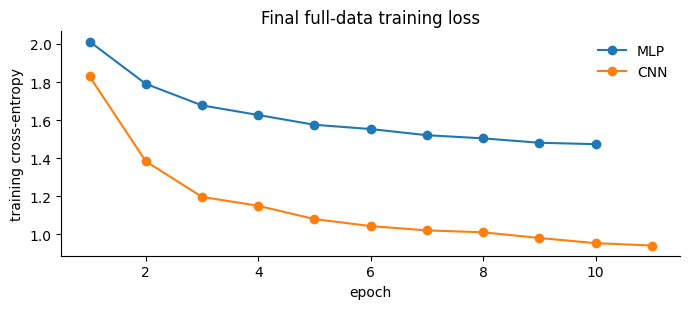

In [30]:
CNN_PARAMS = {"base_filters": 16, "learning_rate": 1e-3, "dropout_rate": 0.3}   # frozen (Section 3)
CNN_EPOCHS = 11                                                                # frozen (Section 3)

cnn_final = build_cnn(**CNN_PARAMS)
cnn_logger = EpochLogger()
t0 = perf_counter()
cnn_history = cnn_final.fit(make_dataset(X_train_img, y_train, training=True), epochs=CNN_EPOCHS,
                            callbacks=[cnn_logger, keras.callbacks.TerminateOnNaN()], verbose=2)
cnn_fit_s = perf_counter() - t0
t0 = perf_counter()
cnn_proba = cnn_final.predict(make_dataset(X_test_img), verbose=0)
cnn_pred_s = perf_counter() - t0
assert cnn_proba.shape == (8000, NUM_CLASSES) and np.allclose(cnn_proba.sum(axis=1), 1, atol=1e-5)
cnn_epoch_log = pd.DataFrame(cnn_logger.records)
cnn_epoch_log.to_csv(RESULTS_DIR / "final_cnn_epochs.csv", index=False)
record_final("CNN", cnn_proba.argmax(axis=1), cnn_fit_s, cnn_pred_s,
             f"f=16, lr=1e-3, dropout=0.3, {CNN_EPOCHS} epochs", cnn_final.count_params(), CNN_EPOCHS)
print(f"Mean time per epoch: {cnn_epoch_log['train_seconds'].mean():.2f}s")
print(classification_report(y_test, final_predictions["CNN"], target_names=SHORT_NAMES, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(mlp_epoch_log["epoch"], mlp_epoch_log["loss"], marker="o", label="MLP")
ax.plot(cnn_epoch_log["epoch"], cnn_epoch_log["loss"], marker="o", label="CNN")
ax.set(xlabel="epoch", ylabel="training cross-entropy", title="Final full-data training loss")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(RESULTS_DIR / "final_training_loss.png"); plt.show()

### Comparison of the final models on the test set

,val_macro_f1,test_accuracy,test_macro_f1,test_balanced_accuracy,fit_seconds,predict_seconds,hyperparameters,parameters,epochs
Dummy,0.0284,0.1467,0.0284,0.1111,0.00,0.0001,strategy=most_frequent,0,–
Nearest Centroid,0.4051,0.4303,0.4105,0.4325,0.14,0.1130,"euclidean, no shrinkage","21,168",–
GaussianNB,0.3749,0.4155,0.3857,0.4307,0.67,1.6347,var_smoothing=1e-06,"42,345",–
MLP,0.4277,0.4849,0.4432,0.4729,33.81,0.5570,"h=256, lr=1e-3, dropout=0, 10 epochs","604,681",10
CNN,0.7276,0.7080,0.6831,0.6882,86.59,0.9797,"f=16, lr=1e-3, dropout=0.3, 11 epochs","106,089",11


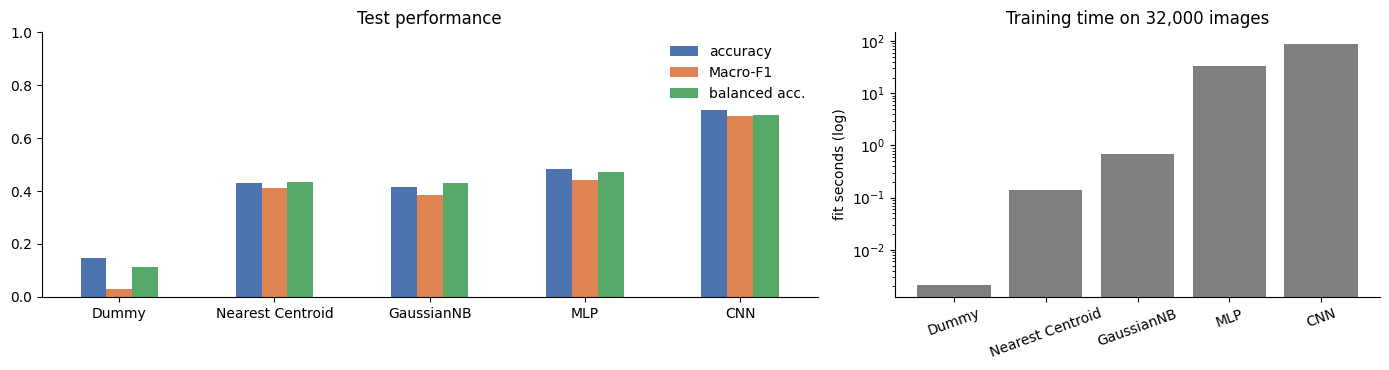

In [31]:
# Validation Macro-F1 of each selected configuration, copied from the Section 3 outputs
# (hard-coded so this cell does not depend on the tuning cells having been run).
VAL_GNB, VAL_MLP, VAL_CNN = 0.3749196062459024, 0.4277240264777863, 0.7276495830991221
VALIDATION_SELECTION = {   # validation Macro-F1 of the selected configuration (Section 3, this run)
    "Dummy": float(baseline_validation.loc["Dummy", "macro_f1"]),
    "Nearest Centroid": float(baseline_validation.loc["Nearest Centroid", "macro_f1"]),
    "GaussianNB": VAL_GNB, "MLP": VAL_MLP, "CNN": VAL_CNN,
}
order = ["Dummy", "Nearest Centroid", "GaussianNB", "MLP", "CNN"]
summary = pd.DataFrame(final_results).T.loc[order]
summary.insert(0, "val_macro_f1", pd.Series(VALIDATION_SELECTION))
summary = summary.rename(columns={"accuracy": "test_accuracy", "macro_f1": "test_macro_f1",
                                  "balanced_accuracy": "test_balanced_accuracy"})
summary.to_csv(RESULTS_DIR / "final_model_comparison.csv")
display(summary.style.format({c: "{:.4f}" for c in ["val_macro_f1", "test_accuracy", "test_macro_f1",
                                                     "test_balanced_accuracy", "predict_seconds"]}
                             | {"fit_seconds": "{:.2f}", "parameters": "{:,.0f}", "epochs": "{:.0f}"}, na_rep="–"))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
summary[["test_accuracy", "test_macro_f1", "test_balanced_accuracy"]].astype(float).plot.bar(
    ax=axes[0], rot=0, ylim=(0, 1), color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Test performance"); axes[0].legend(["accuracy", "Macro-F1", "balanced acc."], frameon=False)
axes[1].bar(order, summary["fit_seconds"].astype(float), color="tab:grey")
axes[1].set_yscale("log"); axes[1].set_ylabel("fit seconds (log)"); axes[1].set_title("Training time on 32,000 images")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "final_comparison.png"); plt.show()

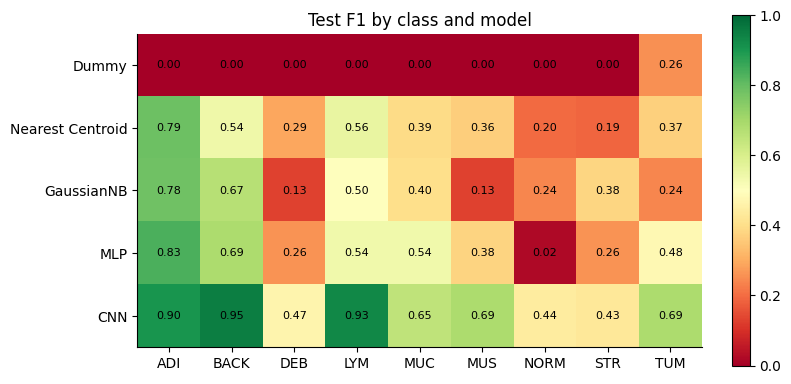

precision                   recall                  
model       CNN GaussianNB    MLP    CNN GaussianNB    MLP
class                                                     
ADI       0.841      0.671  0.744  0.976      0.938  0.947
BACK      0.955      0.690  0.740  0.950      0.645  0.640
DEB       0.605      0.185  0.359  0.380      0.103  0.203
LYM       0.947      0.417  0.416  0.919      0.621  0.755
MUC       0.609      0.348  0.521  0.700      0.475  0.555
MUS       0.714      0.458  0.406  0.662      0.076  0.353
NORM      0.657      0.270  0.233  0.331      0.216  0.010
STR       0.550      0.273  0.268  0.348      0.630  0.251
TUM       0.545      0.387  0.430  0.928      0.174  0.543

In [32]:
# Per-class F1 for every model: where do the gains come from?
per_class = pd.DataFrame({name: f1_score(y_test, final_predictions[name], labels=range(NUM_CLASSES),
                                         average=None, zero_division=0) for name in order},
                         index=SHORT_NAMES)
per_class.to_csv(RESULTS_DIR / "final_per_class_f1.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(per_class.T.values, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), SHORT_NAMES); ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{per_class.iloc[j, i]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Test F1 by class and model"); fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "final_per_class_f1.png"); plt.show()

# Precision vs recall for the three assessed models: which classes are over- or under-predicted?
prec_rec = []
for name in ["GaussianNB", "MLP", "CNN"]:
    report = classification_report(y_test, final_predictions[name], output_dict=True, zero_division=0)
    for k in range(NUM_CLASSES):
        prec_rec.append({"model": name, "class": SHORT_NAMES[k],
                         "precision": report[str(k)]["precision"], "recall": report[str(k)]["recall"]})
prec_rec = pd.DataFrame(prec_rec)
display(prec_rec.pivot(index="class", columns="model", values=["precision", "recall"]).round(3).loc[SHORT_NAMES])

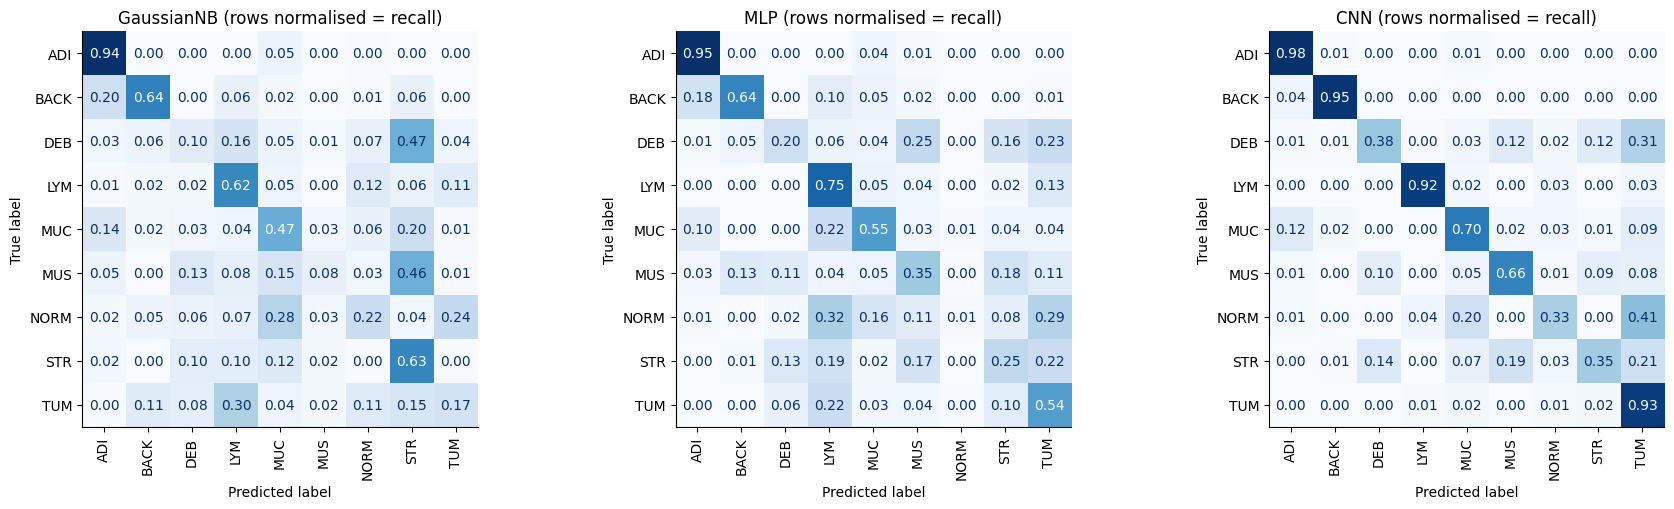

GaussianNB largest confusions (true→predicted, count): MUS→STR (497), DEB→STR (409), TUM→LYM (355), NORM→MUC (193)
       MLP largest confusions (true→predicted, count): TUM→LYM (255), NORM→LYM (219), DEB→MUS (217), NORM→TUM (199)
       CNN largest confusions (true→predicted, count): NORM→TUM (281), DEB→TUM (273), STR→TUM (169), STR→MUS (154)


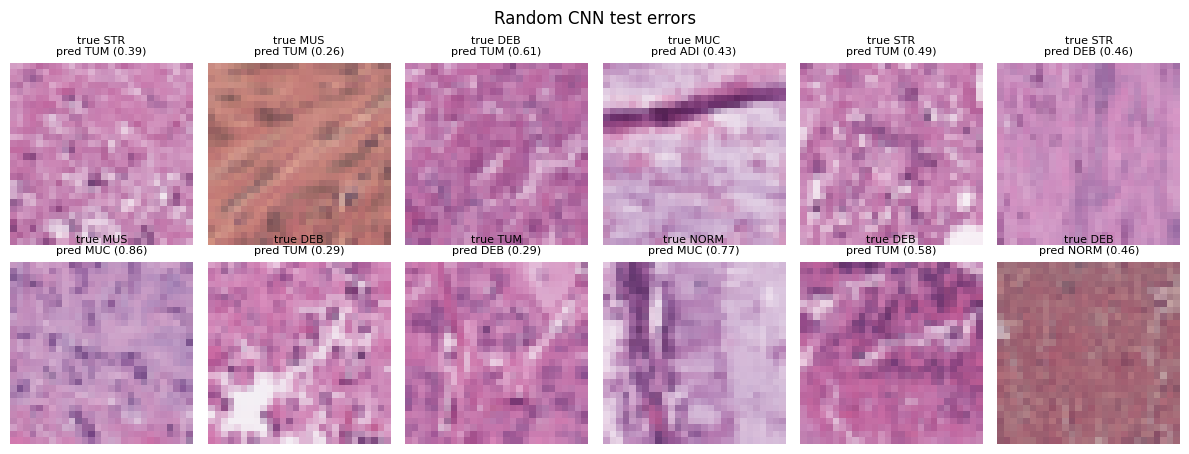

CNN mean max-probability: correct 0.746, wrong 0.497


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, name in zip(axes, ["GaussianNB", "MLP", "CNN"]):
    plot_confusion(name, final_predictions[name], ax=ax)
    ax.tick_params(axis="x", rotation=90)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "final_confusion_matrices.png"); plt.show()

def top_confusions(name, n=4):
    cm = confusion_matrix(y_test, final_predictions[name], labels=range(NUM_CLASSES))
    np.fill_diagonal(cm, 0)
    pairs = sorted(((cm[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)), reverse=True)[:n]
    return [f"{SHORT_NAMES[i]}→{SHORT_NAMES[j]} ({c})" for c, i, j in pairs]
for name in ["GaussianNB", "MLP", "CNN"]:
    print(f"{name:>10} largest confusions (true→predicted, count):", ", ".join(top_confusions(name)))

# A few CNN mistakes with the predicted class and its probability (descriptive only).
wrong = np.flatnonzero(final_predictions["CNN"] != y_test)
chosen = np.random.default_rng(SEED).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for ax, i in zip(axes.ravel(), chosen):
    ax.imshow(X_test_img[i]); ax.axis("off")
    ax.set_title(f"true {SHORT_NAMES[y_test[i]]}\npred {SHORT_NAMES[final_predictions['CNN'][i]]} "
                 f"({cnn_proba[i].max():.2f})", fontsize=8)
fig.suptitle("Random CNN test errors"); fig.tight_layout()
fig.savefig(RESULTS_DIR / "final_cnn_errors.png"); plt.show()
print(f"CNN mean max-probability: correct {cnn_proba.max(1)[final_predictions['CNN'] == y_test].mean():.3f}, "
      f"wrong {cnn_proba.max(1)[wrong].mean():.3f}")

### Reproducibility across hardware platforms

During development the same pipeline was executed on several machines. The table below lists the **recorded** test results from those runs, together with the result computed **in this notebook run** (last row). Every run used identical data files (same SHA-256), the same split, seed, code and hyperparameters. The Docker rows also used byte-identical package versions.

In [34]:
recorded_runs = pd.DataFrame([
    # platform, CPU, software, MLP acc, MLP F1, CNN acc, CNN F1  (recorded from earlier executions)
    ("Windows 11 laptop (development)", "Intel x86-64 (Family 6, Model 189)", "Py 3.11.15, Keras 3.6.0",
     0.496375, 0.449128, np.nan, np.nan),
    ("macOS laptop (development)", "Apple Silicon (arm64)", "Py 3.12.14, Keras 3.5.0",
     np.nan, np.nan, 0.720375, 0.697860),
    ("Docker, WSL2 host", "AMD Ryzen 9 5900HS", "pinned image", 0.489250, 0.438672, 0.739250, 0.723255),
    ("Docker, GitHub-hosted runner (2 of 3 runs)", "Azure VM, CPU model not logged", "pinned image",
     0.484875, 0.443158, 0.708000, 0.683125),
    ("Docker, GitHub-hosted runner (1 of 3 runs)", "Azure VM, CPU model not logged", "pinned image",
     0.489250, 0.438672, 0.739250, 0.723255),
], columns=["platform", "cpu", "software", "MLP_accuracy", "MLP_macro_f1", "CNN_accuracy", "CNN_macro_f1"])
this_run = pd.DataFrame([{
    "platform": f"THIS RUN: {runtime_environment['platform'][:40]}",
    "cpu": runtime_environment["cpu_model"], "software": "pinned stack",
    "MLP_accuracy": final_results["MLP"]["accuracy"], "MLP_macro_f1": final_results["MLP"]["macro_f1"],
    "CNN_accuracy": final_results["CNN"]["accuracy"], "CNN_macro_f1": final_results["CNN"]["macro_f1"]}])
platforms = pd.concat([recorded_runs, this_run], ignore_index=True)
platforms.to_csv(RESULTS_DIR / "cross_platform_results.csv", index=False)
display(platforms.round(4))
for m in ("MLP", "CNN"):
    col = platforms[f"{m}_macro_f1"].dropna()
    print(f"{m}: test Macro-F1 across platforms ranges {col.min():.4f}-{col.max():.4f} "
          f"(spread {col.max() - col.min():.4f}, n={len(col)})")
print("Dummy / Nearest Centroid / GaussianNB were identical on every platform: "
      f"{final_results['Dummy']['macro_f1']:.6f} / {final_results['Nearest Centroid']['macro_f1']:.6f} / "
      f"{final_results['GaussianNB']['macro_f1']:.6f}")

,platform,cpu,software,MLP_accuracy,MLP_macro_f1,CNN_accuracy,CNN_macro_f1
0,Windows 11 laptop (development),"Intel x86-64 (Family 6, Model 189)","Py 3.11.15, Keras 3.6.0",0.4964,0.4491,NaN,NaN
1,macOS laptop (development),Apple Silicon (arm64),"Py 3.12.14, Keras 3.5.0",NaN,NaN,0.7204,0.6979
2,"Docker, WSL2 host",AMD Ryzen 9 5900HS,pinned image,0.4892,0.4387,0.7392,0.7233
3,"Docker, GitHub-hosted runner (2 of 3 runs)","Azure VM, CPU model not logged",pinned image,0.4849,0.4432,0.7080,0.6831
4,"Docker, GitHub-hosted runner (1 of 3 runs)","Azure VM, CPU model not logged",pinned image,0.4892,0.4387,0.7392,0.7233
5,THIS RUN: Linux-6.18.44-fc-v180-x86_64-with-gl...,Intel(R) Xeon(R) Processor @ 2.80GHz,pinned stack,0.4849,0.4432,0.7080,0.6831


MLP: test Macro-F1 across platforms ranges 0.4387-0.4491 (spread 0.0105, n=5)
CNN: test Macro-F1 across platforms ranges 0.6831-0.7233 (spread 0.0401, n=5)
Dummy / Nearest Centroid / GaussianNB were identical on every platform: 0.028438 / 0.410469 / 0.385748


**What we learned from this.**
* The **closed-form models** (Dummy, Nearest Centroid, GaussianNB) gave identical predictions on every platform. Their computation is a short sequence of means, variances and sums, so last-bit rounding differences essentially never flip an arg-max.
* The **networks did not.** The final MLP's training loss matched the Windows laptop run to four decimals for the first two epochs (2.0129, 1.7905) and then drifted. The CNN's trajectories differed from the first epoch. Across platforms, final test Macro-F1 spans about 0.010 for the MLP and about **0.040 for the CNN**, more than the gap between several CNN tuning trials. The ranking CNN ≫ MLP > GaussianNB never changed.
* **The outcomes form clusters tied to the CPU, not random scatter.** This notebook ran on an Intel Xeon with AVX-512 and reproduced, to every printed digit, the result of two earlier CI runs on GitHub-hosted runners (CNN 0.6831, MLP 0.4432). The third CI run instead reproduced the AMD Ryzen workstation (CNN 0.7233, MLP 0.4387) exactly. Hosted runners are drawn from a pool of Intel and AMD machines, and the CNN fit times of those runs differed three- to fivefold. The most consistent explanation is therefore that results depend on which **vector instruction set** the oneDNN/Eigen kernels select. AVX-512, AVX2 and ARM NEON kernels accumulate the same sums in different orders, and floating-point addition is not associative [Goldberg 1991]. The tiny differences are then amplified by ≈ 2,500 Adam steps through ReLU networks. We did not log the CI runners' CPU models at the time, so this attribution is strongly suggested rather than proven. The Setup cell now logs CPU model and SIMD flags for this reason.
* **Docker fixed the software but not the arithmetic.** `enable_op_determinism()` and pinned containers guarantee *run-to-run* identity on one machine (confirmed: two complete runs on the same host gave identical metrics to every digit), not *cross-machine* identity. Truly bit-exact cross-platform results would require forcing one kernel path, for example `TF_ENABLE_ONEDNN_OPTS=0` or a fixed ISA, at a cost in speed. We chose not to do this and instead report the spread.
* **Consequences for how we report.** (i) A single-run CNN difference below ≈ 0.04 Macro-F1 should not be called an improvement. (ii) Our robust conclusions are the model ranking and the per-class error patterns, not the third decimal place. (iii) A proper estimate of run-to-run variability needs multiple seeds; this is the first item of future work.

### Interpretation of the final results

**Ranking.** On the test set, CNN (Macro-F1 0.683) ≫ MLP (0.443) > Nearest Centroid (0.410) > GaussianNB (0.386) ≫ Dummy (0.028). The order of the three assessed models matches the theoretical expectation in Section 2. Two results run against simple intuition and are worth stating plainly:

1. **GaussianNB is worse than the parameter-free Nearest Centroid** (Macro-F1 0.386 vs 0.410). Per-class diagonal variances should be *more* flexible than one mean per class. On data where 2,352 features are this strongly correlated (r ≈ 0.9 between neighbours), however, GNB adds up hundreds of near-duplicate log-likelihood terms. Small variance mismatches then dominate the decision. The symptom is extreme over-confidence: **97 % of GNB's test predictions have a posterior above 0.999**, although only 41.5 % are correct. Its errors flow into a few "attractor" classes. **STR** receives 497 MUS and 409 DEB images, so STR recall is 0.63 while STR precision is only 0.27. **TUM** images are sent to LYM (355). MUS recall collapses to 0.08. These are exactly the closest centroid pairs found in the EDA (MUS–STR, LYM–TUM).
2. **The MLP's 605k parameters buy only +0.03 Macro-F1 over Nearest Centroid.** Its gains are concentrated in the colour- and intensity-separable classes (MUC 0.54, MUS 0.38, TUM 0.48). It essentially **never recognises normal mucosa (NORM F1 0.02, recall 0.01)**, sending those images to LYM (219) and TUM (199). Accuracy (0.485) therefore hides a complete failure on one class, which Macro-F1 and balanced accuracy (0.473) expose.

**Where the CNN gains.** The CNN improves every class, most of all those defined by *texture* rather than colour: BACK 0.69 → 0.95, LYM 0.54 → 0.93, MUS 0.38 → 0.69, TUM 0.48 → 0.69 (MLP → CNN F1). This matches findings 3 and 4: dense small nuclei (LYM) and smooth fibre bundles (MUS) are local patterns that a shared 3×3 filter detects anywhere in the patch. Its remaining weaknesses are **STR (0.43), NORM (0.44) and DEB (0.47)**. Their errors flow mostly *into TUM*: NORM→TUM 281, DEB→TUM 273, STR→TUM 169, so TUM has recall 0.93 but precision 0.55. Biologically this is plausible. Normal mucosa and adenocarcinoma are both glandular epithelium, distinguished mainly by gland architecture over hundreds of micrometres. After down-sampling to 28×28 pixels, much of that architecture is lost, and a receptive field of about 10×10 pixels cannot see it. Debris and cancer-associated stroma are heterogeneous mixtures that share components with tumour tissue.

**Confidence.** The CNN's mean top-class probability is 0.75 for correct and 0.50 for wrong predictions. Its confidence therefore carries usable information, for example to flag uncertain patches for review, whereas GNB's does not.

**Runtime and cost.** Fit times on 32,000 images (2-core CPU): GNB 0.7 s, MLP ≈ 34 s (≈ 3.4 s/epoch × 10), CNN ≈ 87 s (≈ 7.9 s/epoch × 11). The CNN is ≈ 2.3× slower per epoch than the MLP although it has 5.7× fewer parameters. A rough count gives ≈ 1.2 M multiply-adds per image for the two convolutions (each weight reused at 784 or 196 positions) plus 0.1 M for the dense head, against ≈ 0.6 M for the MLP's first layer. This explains the gap: runtime follows compute, not parameter count. Prediction is fast for every model (≤ 2 s for 8,000 images). GNB's prediction is comparatively slow (≈ 1.6 s) because it evaluates 9 × 2,352 Gaussian log-densities per image. The MLP and CNN trade a large training-time advantage for GNB against a 0.30 Macro-F1 gain for the CNN.

**Validation vs test.** The MLP scored 0.428 on validation and 0.443 on test; the CNN scored 0.728 and 0.683. These differences are *not* clean generalisation-gap estimates. The final models were retrained on 25 % more data for a fixed number of epochs (so no epoch selection was "optimistic" on the test set), and they were evaluated on a different partition. For the CNN they also fall within the cross-platform spread shown above. The final CNN's training accuracy (0.65 at epoch 11, measured with dropout active) is below its test accuracy (0.71). This indicates the model is still underfitting rather than overfitting, which suggests that a longer schedule or a larger model would still help.

**Limitations of this evaluation.**
* Single seed and single validation split, with no confidence intervals.
* The 12-epoch cap favours fast-converging configurations.
* The image-level split cannot guarantee that patches from the same slide or patient are not shared between training and test (no slide IDs are provided), which may inflate all scores.
* The course subset with its own split is not directly comparable to published MedMNIST benchmarks.
* Timings come from one 2-core machine and are not hardware-normalised.

**Future work** (each item addresses a limitation above; the report discusses them in more detail).
1. Repeat the final MLP and CNN with 5 seeds on two CPU types and report mean ± s.d., turning the cross-platform spread into a proper uncertainty estimate.
2. Replace the fixed epoch count with learning-rate decay and select the epoch from a seed-averaged validation curve; raise the cap for the slower 3e-4 runs.
3. Give the CNN more spatial context for NORM/STR/TUM (a third convolution block, rotation/flip augmentation) and judge success by NORM/STR recall and TUM precision.
4. Decorrelate the inputs for GaussianNB (PCA to ≈ 50–150 components) to test whether the independence violation explains its poor accuracy and calibration.
5. Centre or standardise the MLP inputs and add batch normalisation to test the dying-ReLU explanation of the collapsed trial.
6. Use slide-level splits if slide IDs become available, to estimate performance on unseen patients.

## 5. AI Acknowledgement
Include acknowledgement of AI usage here.

* **ChatGPT and Codex (OpenAI)** were used throughout the project to interpret the specification and template, debug code for the individual models, write the streaming Macro-F1 metric and timing callbacks, design the Docker environment and reproduction scripts, generate the Streamlit EDA dashboard, and helped test the Docker containers.
* **Claude (Anthropic)** was used to integrate the team's model code into this single notebook following the template, extend the exploratory analysis and search visualisations, test the Docker containers against the Codex results and draft the accompanying discussion and help members structure the main argument of the report.
* All hyperparameter choices, interpretations and numerical claims were checked by the group against the executed outputs in this notebook. Each member's use of AI is described further in the report.

**References (code and data).** MedMNIST v2 / PathMNIST (Yang et al., *Scientific Data* 2023; Kather et al., *PLoS Medicine* 2019); scikit-learn and Keras/TensorFlow API documentation (GaussianNB, NearestCentroid, Dense, Conv2D, Dropout, Adam, EarlyStopping, `enable_op_determinism`); Goldberg (1991), *What every computer scientist should know about floating-point arithmetic*.